# Thrombolysis in mild stroke (NIHSS 1–5) arriving within 4 hours, by individual NIHSS score: target trial emulation by exact matching

## Summary

**Aim.** To estimate the effect of intravenous thrombolysis on a good outcome at hospital discharge in patients with mild ischaemic stroke (NIHSS 1–5) who arrive within 4 hours of onset, separately for each NIHSS score and for three onset-to-thrombolysis windows (< 180, 180–270 and 270–360 minutes).

**Data.** SSNAP stroke admissions in England and Wales, 2020–2025 (cleaned data). 58,389 patients are eligible, from stroke teams that gave at least 10 thrombolyses in the cohort; 13,380 (22.9%) were thrombolysed.

**Design.** Emulation of a target trial. Each thrombolysed patient is exactly matched to an untreated patient with the same pre-stroke mRS, NIHSS score, age, AF diagnosis and anticoagulant use for AF; each control can be used up to 3 times. The estimand is the effect in the treated: the difference in the proportion with a good outcome (discharge mRS 0–2, or no worse than pre-stroke mRS) between matched thrombolysed and untreated patients.

**Main results.**

* 99.6–100% of thrombolysed patients are matched. Matched pairs are identical on the matching features, and the unmatched comorbidities are well balanced (absolute SMD 0.104 or less).
* **No detectable benefit at NIHSS 1 or 2:** −0.3 (95% CI −4.0 to 3.5) and +0.9 (−1.6 to 3.3) percentage points. 83–85% of matched controls already have a good outcome.
* **Benefit from NIHSS 3 upwards, rising with severity:** +4.8 (2.7 to 6.9) at NIHSS 3, +6.6 (4.7 to 8.5) at NIHSS 4 and +8.5 (6.6 to 10.5) at NIHSS 5; +5.7 (4.7 to 6.7) pooled over NIHSS 1–5.
* **Earlier treatment, larger difference:** pooled over NIHSS 1–5, +6.8 points within 180 minutes, +4.6 at 180–270 minutes and +2.1 (−3.1 to 7.3; 475 pairs) at 270–360 minutes.
* **Sensitivity analyses:** across matching choices, cohort definitions, outcome definitions and 20 random seeds, the NIHSS 3–5 CIs always exclude zero and the NIHSS 1 CIs always include zero.
* **Confounding:** the results depend heavily on matching exactly for NIHSS; without it the pooled benefit disappears (+5.7 → −0.2 points). E-values at NIHSS 3–5 are 1.32 to 1.52 and sensemakr robustness values 5.6% to 8.8%, so unmeasured confounding of moderate strength could explain the results.

**Conclusion.** In this cohort, thrombolysis for mild stroke is associated with more good outcomes at discharge from NIHSS 3 upwards, with larger differences at higher NIHSS and with earlier treatment. There is no evidence of benefit at NIHSS 1, and at most a small benefit at NIHSS 2. The findings are consistent across analytic choices, but they rest on matching for stroke severity and are only moderately robust to unmeasured confounding, such as whether the deficit is disabling.

## Target trial and notebook structure

| Protocol component | Target trial | How it is emulated with SSNAP data |
|---|---|---|
| **Eligibility** | Ischaemic stroke, NIHSS 1–5, arriving within 4 hours of known onset, not having thrombectomy | Infarction; onset-to-arrival < 240 min; NIHSS 1–5; no thrombectomy; no perfusion imaging; discharge mRS recorded; stroke team gave at least 10 thrombolyses in the cohort |
| **Treatment strategies** | Thrombolysis within < 180, 180–270 or 270–360 min of onset, vs no thrombolysis | Strategy assigned from the recorded onset-to-thrombolysis time |
| **Assignment** | Random | Not random. Each thrombolysed patient is exactly matched to an untreated patient with the same pre-stroke mRS, NIHSS, age, AF anticoagulant use and AF diagnosis |
| **Outcome** | Good outcome at discharge: mRS 0–2, or no worse than pre-stroke mRS | As in the target trial |
| **Causal contrast** | Effect of thrombolysis in those treated | Difference between matched thrombolysed and untreated patients |
| **Analysis** | Paired difference in proportions with 95% CI; McNemar's test | As in the target trial, by NIHSS and time window, with sensitivity analyses |

### Notebook structure

1. Set-up
2. Cohort selection and treatment groups
3. Matching
4. Good outcome by NIHSS and time window: summary table, headline table, chart
5. Balance of patient characteristics after matching
6. Sensitivity analyses: analytic choices, forest plot, random choice of control, E-values, sensemakr, leave-one-out
7. Summary of observations, conclusions and limitations

Each section describes its methods before the code, and its results after the output.

### References

* Hernán MA, Dahabreh IJ, Dickerman BA, Swanson SA. The target trial framework for causal inference from observational data: why and when is it helpful? *Ann Intern Med* 2025;178:402–407.
* VanderWeele TJ, Ding P. Sensitivity analysis in observational research: introducing the E-value. *Ann Intern Med* 2017;167:268–274.
* Cinelli C, Hazlett C. Making sense of sensitivity: extending omitted variable bias. *J R Stat Soc Series B* 2020;82:39–67.

## 1. Set-up

### Libraries

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats

warnings.filterwarnings("ignore")

### Analysis settings

All analysis choices are set in the cell below. Each sensitivity analysis in section 6 changes one of them.

* **Good outcome:** discharge mRS ≤ 2 (`MRS_TARGET`), or no worse than pre-stroke mRS.
* **Cohort:** NIHSS 1–5 (`NIHSS_VALUES`); arrival within 240 minutes of onset (`MAX_ARRIVAL`); thrombolysis no later than 360 minutes (`MAX_THROMBOLYSIS`); stroke teams that gave at least 10 thrombolyses in the cohort (`MIN_TEAM_THROMBOLYSIS`).
* **Treatment groups:** onset-to-thrombolysis windows ending at 180, 270 and 360 minutes (`TIME_WINDOWS`).
* **Matching:** exact matching on pre-stroke mRS, NIHSS, age, anticoagulant use for AF and AF diagnosis (`MATCHING_FEATURES`); each control used at most 3 times (`MAX_CONTROL_USES`); fixed random seed (`MATCH_SEED`).
* **Balance check:** heart failure, hypertension and diabetes are not matched, but are compared after matching (`BASELINE_FEATURES`).
* **Sentinel time** of 99,999 minutes meaning "not thrombolysed".

Tables and figures are saved to `./output` with the file-name stem in `prefix`.

In [2]:
prefix = "mild_stroke_by_nihss_1_to_5_early_arrival_good_outcome_target_trial"
DATA_PATH = "../data/sam3/cleaned_data_anon_teams.csv"
OUTPUT_DIR = "./output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Outcome
MRS_TARGET = 2                 # good outcome: discharge mRS <= MRS_TARGET, or no worse than pre-stroke mRS

# Cohort
NIHSS_VALUES = [1, 2, 3, 4, 5]
MAX_ARRIVAL = 240              # include patients arriving within this many minutes of onset
MAX_THROMBOLYSIS = 360         # exclude thrombolysis later than this
MIN_TEAM_THROMBOLYSIS = 10     # include teams that gave at least this many thrombolyses in the cohort

# Treatment groups: upper limits (minutes) of the onset-to-thrombolysis windows
TIME_WINDOWS = [180, 270, 360]
CONTROL_GROUP = "No thrombolysis"
ALL_TREATED = "All (≤360 min)"

# Matching
MATCHING_FEATURES = [
    'prior_disability',
    'stroke_severity',
    'age',
    'afib_anticoagulant',
    'any_afib_diagnosis',
]
MAX_CONTROL_USES = 3           # k: maximum times an untreated patient can be a control (None = unlimited)
MATCH_SEED = 42                # base random seed for picking a control

# Baseline features used to check balance after matching
COMORBIDITIES = ['congestive_heart_failure', 'hypertension', 'diabetes']
BASELINE_FEATURES = MATCHING_FEATURES + COMORBIDITIES

NO_TREATMENT = 99999           # sentinel time meaning "not thrombolysed"
TIME_THROMBOLYSIS = "onset_to_thrombolysis_time"

## 2. Cohort selection and treatment groups

### Eligibility

Patients are included if they:

* had an ischaemic stroke (infarction) and a recorded discharge mRS
* arrived within 4 hours (240 minutes) of known stroke onset, so all had time to be assessed for thrombolysis
* did not have perfusion imaging or thrombectomy, so the comparison is thrombolysis versus no thrombolysis only
* had NIHSS 1–5 (mild stroke)
* were treated by a stroke team that gave at least 10 thrombolyses in this cohort

Thrombolysis more than 360 minutes after onset is excluded as implausible. A missing thrombolysis time means thrombolysis was not given.

### Treatment groups

Thrombolysed patients are grouped by onset-to-thrombolysis time: **< 180 min** (≤ 180), **180–270 min** and **270–360 min**. Patients who were not thrombolysed form the control pool.

The cell below defines the good outcome, the treatment groups and the cohort, and prints the number of patients remaining after each selection step.

In [3]:
def good_outcome(df, mrs_target=MRS_TARGET, allow_no_worse_than_prior=True):
    # 1 if discharge mRS <= mrs_target, or (optionally) discharge mRS no worse than pre-stroke mRS
    outcome = df["discharge_disability"] <= mrs_target
    if allow_no_worse_than_prior:
        outcome = outcome | (df["discharge_disability"] <= df["prior_disability"])
    return outcome.astype(int)


def time_group_labels(windows=TIME_WINDOWS):
    # e.g. [180, 270, 360] -> ["<180 min", "180-270 min", "270-360 min"]
    return [f"<{windows[0]} min"] + [f"{a}-{b} min" for a, b in zip(windows[:-1], windows[1:])]


def assign_time_groups(df, windows=TIME_WINDOWS):
    # Onset-to-thrombolysis window; untreated patients (sentinel time) are the control group
    time = df[TIME_THROMBOLYSIS]
    group = pd.Series(CONTROL_GROUP, index=df.index, dtype=object)
    lower = -np.inf
    for label, upper in zip(time_group_labels(windows), windows):
        group[(time > lower) & (time <= upper)] = label
        lower = upper
    df["treatment_group"] = group
    return df


def build_cohort(raw, max_arrival=MAX_ARRIVAL, min_team_thrombolysis=MIN_TEAM_THROMBOLYSIS,
                 exclude_perfusion_imaging=True, verbose=False):
    # Apply eligibility criteria and add outcome, treatment group and patient id.
    # Arguments allow the sensitivity analyses to change one choice at a time.
    df = raw
    log = [("All records", len(df))]

    def keep_rows(label, mask):
        nonlocal df
        df = df[mask]
        log.append((label, len(df)))

    keep_rows("Discharge mRS recorded", df["discharge_disability"].notna())
    keep_rows("Infarction", df["infarction"] == 1)
    keep_rows(f"Arrival within {max_arrival} min of onset", df["onset_to_arrival_time"] < max_arrival)
    if exclude_perfusion_imaging:
        keep_rows("No perfusion imaging", df["perfusion_imaging_used"] == 0)
    keep_rows("No thrombectomy", df["thrombectomy"] == 0)
    keep_rows("NIHSS 1-5", df["stroke_severity"].between(1, 5))

    team_counts = df.groupby("stroke_team")[TIME_THROMBOLYSIS].count()
    eligible_teams = team_counts.index[team_counts >= min_team_thrombolysis]
    keep_rows(f"Team gave >= {min_team_thrombolysis} thrombolyses", df["stroke_team"].isin(eligible_teams))

    df = df.copy()
    df[TIME_THROMBOLYSIS] = df[TIME_THROMBOLYSIS].fillna(NO_TREATMENT)  # missing time = not thrombolysed
    keep_rows(f"Thrombolysis (if given) <= {MAX_THROMBOLYSIS} min",
              (df[TIME_THROMBOLYSIS] <= MAX_THROMBOLYSIS) | (df[TIME_THROMBOLYSIS] == NO_TREATMENT))

    df = df.copy()
    df["outcome_target"] = good_outcome(df)
    df = assign_time_groups(df)
    df["patient_id"] = np.arange(len(df))

    if verbose:
        display(pd.DataFrame(log, columns=["Step", "Patients remaining"]))
    return df


raw_data = pd.read_csv(DATA_PATH, low_memory=False)
data = build_cohort(raw_data, verbose=True)

,Step,Patients remaining
0,All records,452863
1,Discharge mRS recorded,438589
2,Infarction,384365
3,Arrival within 240 min of onset,135944
4,No perfusion imaging,133895
5,No thrombectomy,125703
6,NIHSS 1-5,58514
7,Team gave >= 10 thrombolyses,58458
8,Thrombolysis (if given) <= 360 min,58389


### Patients in each NIHSS score and treatment group

Cross-tabulation of NIHSS score and treatment group in the eligible cohort, before matching.

In [4]:
# Patients available before matching, by NIHSS and treatment group
pd.crosstab(data["stroke_severity"], data["treatment_group"], margins=True)

treatment_group,180-270 min,270-360 min,<180 min,No thrombolysis,All
stroke_severity,,,,,
1.0,341,34,347,10280,11002
2.0,732,90,925,12398,14145
3.0,1162,98,1525,10071,12856
4.0,1601,131,2220,7016,10968
5.0,1678,123,2373,5244,9418
All,5514,476,7390,45009,58389


**Results.**

* Of 452,863 records in the cleaned data, 58,389 patients are eligible. The largest exclusions are arrival 4 hours or more after onset or with unknown onset time (248,421 records), NIHSS outside 1–5 (67,189), stroke types other than infarction (54,224) and thrombectomy (8,192). Every patient with perfusion imaging also had thrombectomy, so the perfusion-imaging criterion removes no extra patients.
* 13,380 patients (22.9%) were thrombolysed: 7,390 within 180 minutes, 5,514 at 180–270 minutes and 476 at 270–360 minutes.
* The proportion thrombolysed rises steeply with NIHSS, from 6.6% at NIHSS 1 to 44.3% at NIHSS 5. Untreated patients are therefore mostly NIHSS 1–3.
* The 270–360 minute group is small (34 to 131 patients per NIHSS score), so its estimates will be imprecise.

## 3. Matching

Treatment was not randomised, so thrombolysed and untreated patients differ; for example, patients with higher NIHSS are much more likely to be thrombolysed. To make a fair comparison, each thrombolysed patient is matched to one untreated patient who is similar before treatment.

**Method:**

* **Exact matching** on all matching features. NIHSS is matched exactly, so every matched pair sits within a single NIHSS score, and results can be split by NIHSS without re-matching.
* **Random choice:** if several untreated patients match, one is picked at random (seed `MATCH_SEED + n` for the *n*-th treated patient in each group, so results are reproducible).
* **Limited reuse of controls:** each untreated patient can be a control at most *k* = `MAX_CONTROL_USES` (3) times. The limit is **shared across the three time windows**, so the order of matching matters. Groups are matched in the order 180–270, 270–360, then < 180 min (alphabetical order of the labels), with patients in data order within each group.
* **Unmatched patients:** a treated patient with no available match (no exact match, or all matching controls already used *k* times) is dropped.

Untreated patients are pre-grouped by matching features, which gives the same matches as a row-by-row search but runs much faster.

The result estimates the effect of thrombolysis **in the treated**: how outcomes for thrombolysed patients compare with what would be expected had similar patients not been thrombolysed. The cell below matches the patients and shows the matching rate in each group, the reasons patients were not matched, and how often controls were reused.

In [5]:
def match_patients(df, matching_features=MATCHING_FEATURES, max_control_uses=MAX_CONTROL_USES,
                   base_seed=MATCH_SEED, group_order=None):
    # Exact 1:1 matching with a shared limit on control reuse.
    # Returns (matched, unmatched, control_use_count):
    #   matched[group] = {"treated": df, "untreated": df, "n_treated_total": int}, row i paired with row i
    #   unmatched = one row per treated patient left unmatched, with the reason
    matching_features = list(matching_features)
    untreated = df[df["treatment_group"] == CONTROL_GROUP]
    if group_order is None:
        group_order = sorted(g for g in df["treatment_group"].unique() if g != CONTROL_GROUP)

    # Row positions of untreated patients for each combination of matching features (data order kept)
    untreated_lookup = untreated.groupby(matching_features, sort=False).indices
    control_use_count = np.zeros(len(untreated), dtype=int)
    max_uses = np.inf if max_control_uses is None else max_control_uses

    matched, unmatched = {}, []
    for group_name in group_order:
        treated = df[df["treatment_group"] == group_name]
        if treated.empty:
            continue
        treated_positions, untreated_positions = [], []
        for count, key in enumerate(treated[matching_features].itertuples(index=False, name=None), start=1):
            candidates = untreated_lookup.get(key)
            if candidates is None or len(candidates) == 0:
                reason = "no exact match"
            else:
                available = candidates[control_use_count[candidates] < max_uses]
                if len(available) > 0:
                    chosen = pd.Series(available).sample(n=1, random_state=base_seed + count).iloc[0]
                    control_use_count[chosen] += 1
                    treated_positions.append(count - 1)
                    untreated_positions.append(chosen)
                    continue
                reason = f"all matching controls used {max_control_uses} times"
            unmatched.append({"treatment_group": group_name,
                              "stroke_severity": treated["stroke_severity"].iloc[count - 1],
                              "reason": reason})

        matched[group_name] = {
            "treated": treated.iloc[treated_positions].reset_index(drop=True),
            "untreated": untreated.iloc[untreated_positions].reset_index(drop=True),
            "n_treated_total": len(treated),
        }
    return matched, pd.DataFrame(unmatched, columns=["treatment_group", "stroke_severity", "reason"]), control_use_count


def make_pairs(matched):
    # One row per matched pair, with what is needed to recompute outcomes in sensitivity analyses
    pairs = []
    for group_name, s in matched.items():
        t, u = s["treated"], s["untreated"]
        pairs.append(pd.DataFrame({
            "treatment_group": group_name,
            "stroke_severity": t["stroke_severity"].astype(int),
            "treated_outcome": t["outcome_target"].astype(int),
            "untreated_outcome": u["outcome_target"].astype(int),
            "treated_mrs": t["discharge_disability"],
            "untreated_mrs": u["discharge_disability"],
            "treated_prior_mrs": t["prior_disability"],
            "untreated_prior_mrs": u["prior_disability"],
            "control_id": u["patient_id"].to_numpy(),
        }))
    return pd.concat(pairs, ignore_index=True)


matched_samples, unmatched, control_use_count = match_patients(data)
pairs = make_pairs(matched_samples)
treated_all = data[data["treatment_group"] != CONTROL_GROUP]

# Matching summary
matching_summary = pd.DataFrame([
    {"treatment_group": g, "treated": s["n_treated_total"], "matched": len(s["treated"]),
     "percent_matched": round(100 * len(s["treated"]) / s["n_treated_total"], 2)}
    for g, s in matched_samples.items()
])
display(matching_summary)
display(unmatched.groupby(["treatment_group", "reason"]).size().rename("unmatched").to_frame())

used = control_use_count[control_use_count > 0]
print(f"Total matched pairs: {len(pairs)}")
print(f"Distinct controls used: {len(used)}; total control slots: {used.sum()}")
print("Number of controls by times used:")
print(pd.Series(used).value_counts().sort_index().rename_axis("times used").to_string())

,treatment_group,treated,matched,percent_matched
0,180-270 min,5514,5512,99.96
1,270-360 min,476,475,99.79
2,<180 min,7390,7362,99.62


unmatched
treatment_group reason                                       
180-270 min     no exact match                              2
270-360 min     no exact match                              1
<180 min        all matching controls used 3 times         16
                no exact match                             12

Total matched pairs: 13349
Distinct controls used: 9749; total control slots: 13349
Number of controls by times used:
times used
1    7022
2    1854
3     873


**Results.**

* **Matching rates:** 99.6–100% of thrombolysed patients are matched in each time window, so the matched pairs represent almost all treated patients.
* **Unmatched patients:** 31 patients are unmatched. 15 had no exact match; 16, all in the < 180 min group (matched last), had matching controls who had all already been used 3 times.
* **Control reuse:** 9,749 distinct controls fill 13,349 pairs. 7,022 are used once, 1,854 twice and 873 the maximum 3 times.

## 4. Good outcome by NIHSS and time window

For each NIHSS score (and pooled NIHSS 1–5) and each time window (and all thrombolysed patients combined), the matched pairs are compared:

* **Good outcome in each arm**, with 95% Wilson score confidence intervals (`wilson_ci`). The Wilson interval stays accurate with small samples and proportions near 0% or 100%, and cannot go outside 0–100%.
* **Difference** (treated minus control, percentage points): the mean of the per-pair differences, which are −1, 0 or +1, with 95% CI = mean ± *t* × SD / √*n* (`paired_difference_ci`). It uses the pairing.
* **P value** from McNemar's test (`mcnemar_p`), which compares the two kinds of discordant pairs: treated good / control poor versus treated poor / control good. The exact binomial version is used when there are fewer than 25 discordant pairs.

**Interpretation notes:**

* Overlap between the treated and control intervals is not a test of the difference; use the difference CI and the McNemar P value.
* An untreated patient can appear in up to three pairs. Neither the intervals nor the P values allow for this, so they may be slightly too narrow. Section 6.1 repeats the analysis with CIs clustered on the control.
* P values are **not adjusted for multiple comparisons**. With 24 rows, some "significant" or "non-significant" results in small rows may be due to chance.

The cell below computes these statistics for every combination of NIHSS and time window and saves them; the tables and chart follow.

In [6]:
def wilson_ci(values, alpha=0.05):
    # Proportion and Wilson score CI for a 0/1 outcome
    values = np.asarray(values, dtype=float)
    n = len(values)
    if n == 0:
        return np.nan, np.nan, np.nan
    p = values.mean()
    z = stats.norm.ppf(1 - alpha / 2)
    denominator = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denominator
    half_width = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denominator
    return p, centre - half_width, centre + half_width


def paired_difference_ci(treated, untreated, alpha=0.05):
    # Mean of per-pair differences (treated - untreated) with t-based CI
    differences = np.asarray(treated, dtype=float) - np.asarray(untreated, dtype=float)
    n = len(differences)
    mean = differences.mean()
    half_width = stats.t.ppf(1 - alpha / 2, n - 1) * differences.std(ddof=1) / np.sqrt(n)
    return mean, mean - half_width, mean + half_width


def mcnemar_p(treated, untreated):
    # McNemar test: exact binomial if < 25 discordant pairs, otherwise continuity-corrected chi-square
    treated_only = int(((treated == 1) & (untreated == 0)).sum())
    untreated_only = int(((treated == 0) & (untreated == 1)).sum())
    discordant = treated_only + untreated_only
    if discordant == 0:
        return 1.0, treated_only, untreated_only
    if discordant < 25:
        p = stats.binomtest(treated_only, discordant, 0.5).pvalue
    else:
        p = stats.chi2.sf((abs(treated_only - untreated_only) - 1) ** 2 / discordant, 1)
    return p, treated_only, untreated_only


def analyse(df, nihss_label, group_label, n_treated_total):
    # All statistics for one set of matched pairs
    treated = df["treated_outcome"].to_numpy()
    untreated = df["untreated_outcome"].to_numpy()
    n = len(df)
    row = {
        "nihss": nihss_label,
        "treatment_group": group_label,
        "treated_n_before_matching": n_treated_total,
        "matched_n": n,
        "percent_matched": 100 * n / n_treated_total if n_treated_total else np.nan,
    }
    if n < 2:
        return row

    t_mean, t_lo, t_hi = wilson_ci(treated)
    u_mean, u_lo, u_hi = wilson_ci(untreated)
    d_mean, d_lo, d_hi = paired_difference_ci(treated, untreated)
    p_mcn, treated_only, untreated_only = mcnemar_p(treated, untreated)
    row.update({
        "treated_good_outcome": t_mean,
        "treated_ci_lower": t_lo,
        "treated_ci_upper": t_hi,
        "treated_std": treated.std(ddof=1),
        "untreated_good_outcome": u_mean,
        "untreated_ci_lower": u_lo,
        "untreated_ci_upper": u_hi,
        "untreated_std": untreated.std(ddof=1),
        "difference": d_mean,
        "difference_ci_lower": d_lo,
        "difference_ci_upper": d_hi,
        "pairs_treated_only_good": treated_only,
        "pairs_untreated_only_good": untreated_only,
        "p_value_mcnemar": p_mcn,
    })
    return row


group_order = [ALL_TREATED] + time_group_labels()
nihss_order = [str(n) for n in NIHSS_VALUES] + ["1-5"]


def select(df, nihss_label, group_label=ALL_TREATED):
    # Rows of pairs (or treated patients) for one NIHSS label and time group
    if nihss_label != "1-5":
        df = df[df["stroke_severity"] == int(nihss_label)]
    if group_label != ALL_TREATED:
        df = df[df["treatment_group"] == group_label]
    return df


results_df = pd.DataFrame([
    analyse(select(pairs, nihss_label, group_label), nihss_label, group_label,
            len(select(treated_all, nihss_label, group_label)))
    for nihss_label in nihss_order
    for group_label in group_order
])
results_df.to_csv(f"{OUTPUT_DIR}/{prefix}_summary_full.csv", index=False)

### 4.1 Summary table

One row per NIHSS score and time window. "Treated (n)" is the number of thrombolysed patients before matching, and "Treated matched (%)" the percentage of them matched. Good outcome is % (95% Wilson CI); the difference is treated minus control in percentage points (95% paired CI). The "1-5" rows pool all NIHSS scores.

In [7]:
def fmt_pct(mean, lower, upper):
    if pd.isna(mean):
        return "-"
    if pd.isna(lower):
        return f"{100 * mean:.1f}"
    return f"{100 * mean:.1f} ({100 * lower:.1f}, {100 * upper:.1f})"


def fmt_p(p):
    if pd.isna(p):
        return "-"
    return "<0.001" if p < 0.001 else f"{p:.3f}"


def fmt_cols(df, prefix_col):
    return [fmt_pct(m, l, u) for m, l, u in zip(
        df[prefix_col[0]], df[prefix_col[1]], df[prefix_col[2]])]


summary_table = pd.DataFrame({
    "NIHSS": results_df["nihss"],
    "Onset to thrombolysis": results_df["treatment_group"],
    "Treated (n)": results_df["treated_n_before_matching"],
    "Matched pairs (n)": results_df["matched_n"],
    "Treated matched (%)": results_df["percent_matched"].apply(lambda v: "-" if pd.isna(v) else f"{v:.1f}"),
    "Treated good outcome, % (95% CI)": fmt_cols(results_df, ("treated_good_outcome", "treated_ci_lower", "treated_ci_upper")),
    "Control good outcome, % (95% CI)": fmt_cols(results_df, ("untreated_good_outcome", "untreated_ci_lower", "untreated_ci_upper")),
    "Difference, % points (95% CI)": fmt_cols(results_df, ("difference", "difference_ci_lower", "difference_ci_upper")),
    "P value (McNemar)": results_df["p_value_mcnemar"].apply(fmt_p),
})
summary_table.to_csv(f"{OUTPUT_DIR}/{prefix}_summary_table.csv", index=False)

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 250)
display(summary_table)

,NIHSS,Onset to thrombolysis,Treated (n),Matched pairs (n),Treated matched (%),"Treated good outcome, % (95% CI)","Control good outcome, % (95% CI)","Difference, % points (95% CI)",P value (McNemar)
0,1,All (≤360 min),722,722,100.0,"84.6 (81.8, 87.1)","84.9 (82.1, 87.3)","-0.3 (-4.0, 3.5)",0.942
1,1,<180 min,347,347,100.0,"86.2 (82.1, 89.4)","87.0 (83.1, 90.2)","-0.9 (-6.2, 4.4)",0.830
2,1,180-270 min,341,341,100.0,"83.6 (79.3, 87.1)","82.7 (78.3, 86.3)","0.9 (-4.7, 6.5)",0.837
3,1,270-360 min,34,34,100.0,"79.4 (63.2, 89.7)","85.3 (69.9, 93.6)","-5.9 (-25.0, 13.2)",0.754
4,2,All (≤360 min),1747,1745,99.9,"83.7 (81.9, 85.4)","82.9 (81.0, 84.6)","0.9 (-1.6, 3.3)",0.514
5,2,<180 min,925,923,99.8,"84.2 (81.7, 86.4)","82.1 (79.5, 84.5)","2.1 (-1.2, 5.3)",0.244
6,2,180-270 min,732,732,100.0,"83.6 (80.8, 86.1)","83.1 (80.2, 85.6)","0.5 (-3.2, 4.3)",0.832
7,2,270-360 min,90,90,100.0,"80.0 (70.6, 87.0)","88.9 (80.7, 93.9)","-8.9 (-19.1, 1.4)",0.134
8,3,All (≤360 min),2785,2781,99.9,"81.5 (80.0, 82.9)","76.7 (75.1, 78.2)","4.8 (2.7, 6.9)",<0.001
9,3,<180 min,1525,1522,99.8,"81.9 (79.9, 83.7)","76.9 (74.8, 79.0)","4.9 (2.2, 7.7)",<0.001


**Results.**

* **By time window (pooled NIHSS 1–5):** the difference is largest with the earliest treatment:
  * < 180 min: +6.8 points (5.4 to 8.1)
  * 180–270 min: +4.6 points (3.0 to 6.2)
  * 270–360 min: +2.1 points (−3.1 to 7.3); the CI includes zero
* **NIHSS 5:** the time effect is clearest here: +10.9 points (8.3 to 13.4) within 180 min vs +5.2 (2.1 to 8.3) at 180–270 min.
* **NIHSS 3 and 4:** the difference is similar in the first two windows (about +5 and +6.5 points).
* **270–360 min rows:** these are small (34–131 pairs per NIHSS score), with very wide CIs. The −8.9 points at NIHSS 2 (−19.1 to 1.4) is most likely chance, given the number of comparisons.
* **NIHSS 1 and 2:** no time window shows a clear difference.

### 4.2 Headline table: all thrombolysed patients (≤ 360 min) by NIHSS

The rows of the summary table for all thrombolysed patients combined, one row per NIHSS score.

In [8]:
headline_table = (summary_table[summary_table["Onset to thrombolysis"] == ALL_TREATED]
                  .drop(columns="Onset to thrombolysis"))
headline_table.to_csv(f"{OUTPUT_DIR}/{prefix}_summary_table_all_treated.csv", index=False)
display(headline_table.reset_index(drop=True))

,NIHSS,Treated (n),Matched pairs (n),Treated matched (%),"Treated good outcome, % (95% CI)","Control good outcome, % (95% CI)","Difference, % points (95% CI)",P value (McNemar)
0,1,722,722,100.0,"84.6 (81.8, 87.1)","84.9 (82.1, 87.3)","-0.3 (-4.0, 3.5)",0.942
1,2,1747,1745,99.9,"83.7 (81.9, 85.4)","82.9 (81.0, 84.6)","0.9 (-1.6, 3.3)",0.514
2,3,2785,2781,99.9,"81.5 (80.0, 82.9)","76.7 (75.1, 78.2)","4.8 (2.7, 6.9)",<0.001
3,4,3952,3929,99.4,"76.4 (75.0, 77.7)","69.8 (68.3, 71.2)","6.6 (4.7, 8.5)",<0.001
4,5,4174,4172,100.0,"71.8 (70.5, 73.2)","63.3 (61.9, 64.8)","8.5 (6.6, 10.5)",<0.001
5,1-5,13380,13349,99.8,"77.4 (76.7, 78.1)","71.7 (71.0, 72.5)","5.7 (4.7, 6.7)",<0.001


**Results.**

* **NIHSS 1 and 2:** no detectable difference: −0.3 (−4.0 to 3.5) and +0.9 (−1.6 to 3.3) percentage points. Untreated patients already do well (84.9% and 82.9% good outcome), so there is little room for improvement. The CIs rule out a benefit larger than about 3.5 points.
* **NIHSS 3 to 5:** the difference rises steadily with NIHSS: +4.8 (2.7 to 6.9), +6.6 (4.7 to 8.5) and +8.5 (6.6 to 10.5) points, all with *p* < 0.001.
* **NIHSS 5:** only 63.3% of controls have a good outcome, and thrombolysis is associated with 8.5 more patients per 100 having a good outcome (71.8%).
* **Pooled NIHSS 1–5:** 77.4% vs 71.7%, +5.7 points (4.7 to 6.7).

### 4.3 Chart: good outcome by treatment time and NIHSS

One panel per onset-to-thrombolysis window (and all thrombolysed patients), with NIHSS along the x-axis. Points show the proportion with a good outcome in thrombolysed patients and their matched controls, with 95% Wilson CIs. The pooled NIHSS 1–5 result is at the right of each panel. Numbers above each pair are McNemar P values (bold if < 0.05, unadjusted).

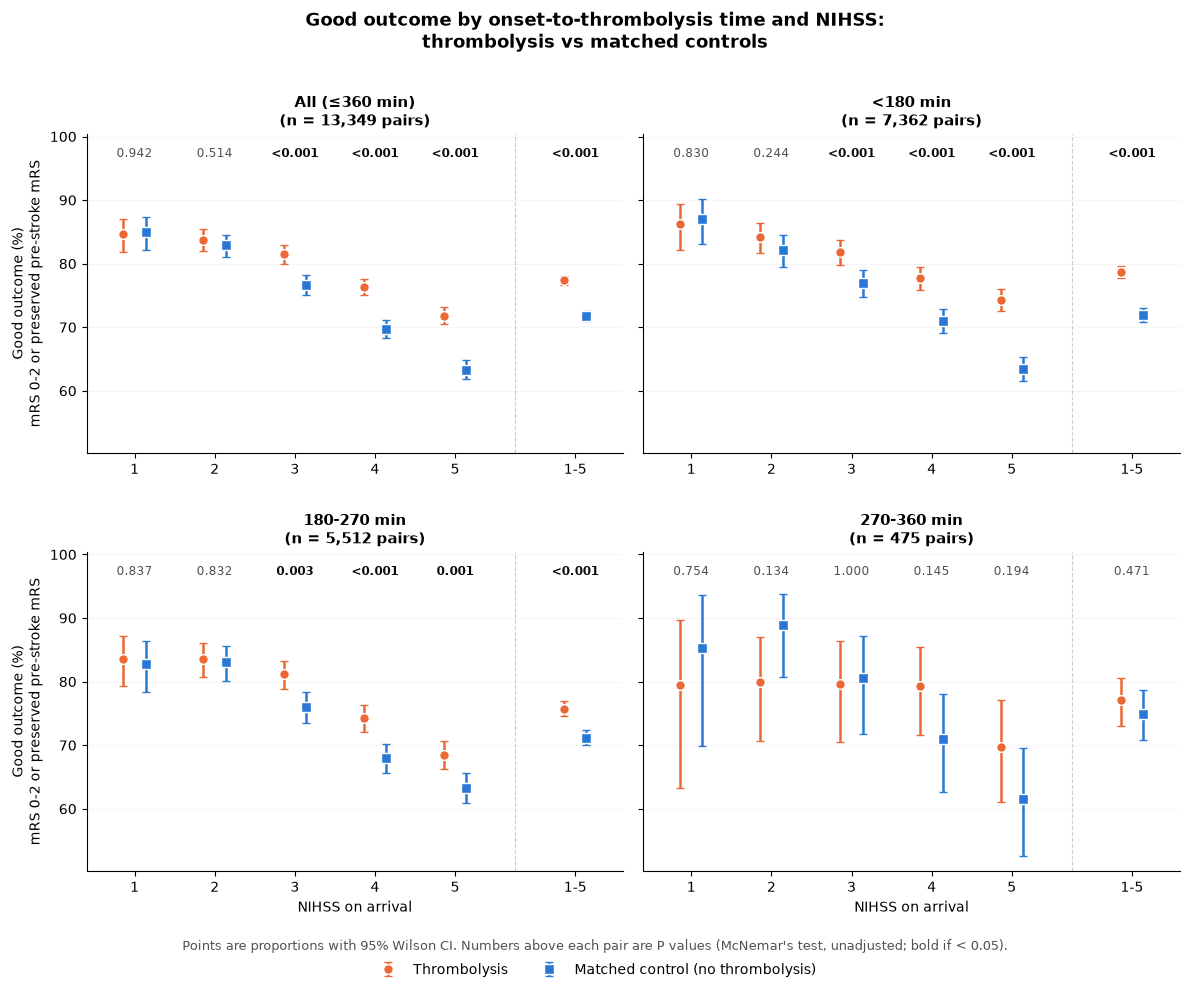

In [9]:
C_TREATED, C_CONTROL = "#eb6834", "#2a78d6"
INK, MUTED = "#0b0b0b", "#52514e"
OFFSET = 0.14

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharey=True)

# Shared y-range across panels, with headroom for P values
y_low = 100 * np.nanmin(results_df[["treated_ci_lower", "untreated_ci_lower"]].to_numpy())
y_high = 100 * np.nanmax(results_df[["treated_ci_upper", "untreated_ci_upper"]].to_numpy())
y_span = y_high - y_low
y_text = y_high + 0.06 * y_span

x = np.arange(len(nihss_order), dtype=float)
x[-1] += 0.5  # gap before the pooled NIHSS 1-5 result

for ax, group_label in zip(axes.flat, group_order):
    df = results_df[results_df["treatment_group"] == group_label].set_index("nihss").reindex(nihss_order)

    for suffix, offset, colour, marker, label in [
        ("treated", -OFFSET, C_TREATED, "o", "Thrombolysis"),
        ("untreated", OFFSET, C_CONTROL, "s", "Matched control (no thrombolysis)"),
    ]:
        mean = 100 * df[f"{suffix}_good_outcome"].to_numpy(dtype=float)
        lower = 100 * df[f"{suffix}_ci_lower"].to_numpy(dtype=float)
        upper = 100 * df[f"{suffix}_ci_upper"].to_numpy(dtype=float)
        ax.errorbar(x + offset, mean, yerr=[mean - lower, upper - mean],
                    fmt=marker, color=colour, ecolor=colour, markersize=7,
                    markeredgecolor="white", markeredgewidth=1,
                    capsize=3, elinewidth=1.8, label=label, zorder=3)

    for xi, p_value in zip(x, df["p_value_mcnemar"]):
        if pd.isna(p_value):
            continue
        ax.text(xi, y_text, fmt_p(p_value), ha="center", va="bottom", fontsize=8.5,
                fontweight="bold" if p_value < 0.05 else "normal",
                color=INK if p_value < 0.05 else MUTED)

    # Divider between individual NIHSS scores and pooled result
    ax.axvline((x[-2] + x[-1]) / 2, color="0.8", lw=0.8, linestyle="--", zorder=0)

    n_pairs = df.loc["1-5", "matched_n"]
    ax.set_title(f"{group_label}\n(n = {int(n_pairs):,} pairs)", fontweight="bold", fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels(nihss_order)
    ax.set_xlim(x[0] - 0.6, x[-1] + 0.6)
    ax.grid(axis="y", alpha=0.3, linestyle=":")
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

axes[0, 0].set_ylim(y_low - 0.06 * y_span, y_text + 0.10 * y_span)
for ax in axes[:, 0]:
    ax.set_ylabel(f"Good outcome (%)\nmRS 0-{MRS_TARGET} or preserved pre-stroke mRS")
for ax in axes[-1, :]:
    ax.set_xlabel("NIHSS on arrival")

handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.0))
fig.suptitle("Good outcome by onset-to-thrombolysis time and NIHSS:\nthrombolysis vs matched controls",
             fontweight="bold", fontsize=13)
fig.text(0.5, 0.04, "Points are proportions with 95% Wilson CI. Numbers above each pair are P values "
         "(McNemar's test, unadjusted; bold if < 0.05).", ha="center", fontsize=9, color=MUTED)
fig.tight_layout(rect=(0, 0.06, 1, 0.97), h_pad=2.5)
fig.savefig(f"{OUTPUT_DIR}/{prefix}.png", dpi=300)
plt.show()

**Results.**

* **Control outcomes** (blue) fall steeply from NIHSS 1 to 5.
* **Treated outcomes** (orange) fall less steeply, so the gap between them opens from NIHSS 3 onwards.
* **The gap is widest** in the < 180 min panel.
* **In the 270–360 min panel**, the points for each NIHSS score have wide, overlapping CIs, reflecting the small numbers.

## 5. Balance of patient characteristics after matching

Matching features should be identical within pairs. Comorbidities (heart failure, hypertension, diabetes) are **not** matched, so this checks how similar matched treated and control patients are on them. Balance is measured with the standardised mean difference, $SMD = (\bar{x}_T - \bar{x}_C) / \sqrt{(s_T^2 + s_C^2)/2}$; an absolute SMD below 0.1 is usually taken as good balance. The table shows SMDs for baseline features (rows) by NIHSS score (columns).

In [10]:
def smd(treated, untreated):
    treated, untreated = pd.to_numeric(treated, errors="coerce"), pd.to_numeric(untreated, errors="coerce")
    pooled_sd = np.sqrt((treated.std() ** 2 + untreated.std() ** 2) / 2)
    return (treated.mean() - untreated.mean()) / pooled_sd if pooled_sd > 0 else 0.0


matched_treated = pd.concat([s["treated"] for s in matched_samples.values()], ignore_index=True)
matched_untreated = pd.concat([s["untreated"] for s in matched_samples.values()], ignore_index=True)

balance = {}
for nihss_label in nihss_order:
    keep = (np.ones(len(matched_treated), dtype=bool) if nihss_label == "1-5"
            else (matched_treated["stroke_severity"] == int(nihss_label)).to_numpy())
    balance[f"NIHSS {nihss_label}"] = {
        feature: smd(matched_treated.loc[keep, feature], matched_untreated.loc[keep, feature])
        for feature in BASELINE_FEATURES
    }
balance_table = pd.DataFrame(balance).round(3)
balance_table.to_csv(f"{OUTPUT_DIR}/{prefix}_balance_smd.csv")
balance_table

,NIHSS 1,NIHSS 2,NIHSS 3,NIHSS 4,NIHSS 5,NIHSS 1-5
prior_disability,0.000,0.000,0.000,0.000,0.000,0.000
stroke_severity,0.000,0.000,0.000,0.000,0.000,0.000
age,0.000,0.000,0.000,0.000,0.000,0.000
afib_anticoagulant,0.000,0.000,0.000,0.000,0.000,0.000
any_afib_diagnosis,0.000,0.000,0.000,0.000,0.000,0.000
congestive_heart_failure,-0.037,-0.018,-0.030,0.006,-0.001,-0.009
hypertension,-0.028,-0.060,-0.033,-0.062,-0.037,-0.046
diabetes,-0.074,-0.104,-0.088,-0.103,-0.029,-0.075


**Results.**

* **Matching features** are perfectly balanced (SMD 0), as expected with exact matching.
* **Unmatched comorbidities** are well balanced:
  * heart failure: −0.04 to +0.01
  * hypertension: −0.03 to −0.06
  * diabetes: −0.03 to −0.10

**Discussion.** Thrombolysed patients are slightly less likely to have diabetes than their matched controls (pooled SMD −0.075, just reaching −0.10 at NIHSS 2 and 4). Diabetes is linked to worse outcomes, so this small imbalance would slightly favour thrombolysis. Section 6.1 tests this by also matching on comorbidities.

## 6. Sensitivity analyses

These analyses test whether the main results (the difference in good outcome for all thrombolysed patients, by NIHSS) depend on choices made in the analysis. Each one changes **one** choice and keeps everything else as in the primary analysis. All results are for **all thrombolysed patients (≤ 360 min)**, by NIHSS.

| Category | Analysis | Why |
|---|---|---|
| Inference | Cluster-robust CI | Pairs sharing a control are not independent. Standard errors are clustered on the control patient. |
| Matching | Controls used once only / up to 5 times / unlimited | Tests the choice of `MAX_CONTROL_USES` (k = 3). |
| Matching | Reverse matching order of time windows | The reuse limit is shared across windows, so the matching order could matter. |
| Matching | Also match on heart failure, hypertension, diabetes | Tests confounding by comorbidities that are not matched. |
| Matching | Also match on large vessel occlusion (LVO) | A mild deficit caused by an LVO has a worse prognosis, and LVO status may affect the decision to thrombolyse. Only patients with LVO recorded can be matched. |
| Cohort | Arrival within 180 min | Patients arriving later in the 4-hour window have less time to be treated, so untreated late arrivals may differ from treated ones. |
| Cohort | All teams / teams with at least 20 thrombolyses | Tests the team thrombolysis-volume restriction (at least 10). |
| Outcome | mRS 0–2 only; mRS 0–1 only; mRS 0–1 or no worse than pre-stroke; mRS 0–3 or no worse than pre-stroke | mRS 0–1 (excellent outcome) is the usual outcome in trials of mild stroke; mRS 0–3 is a looser definition. |
| Matching | 20 random seeds (6.3) | The control is picked at random, so the estimate varies with the seed. |
| Unmeasured confounding | E-values (6.4) and sensemakr (6.5) | How strong an unmeasured confounder would have to be to explain away the result. |
| Measured confounding | Leave one confounder out (6.6) | How much each result depends on matching for NIHSS, age and pre-stroke mRS. |

Matching on exact NIHSS is already the primary analysis, so it is not a sensitivity analysis here. Including patients who had perfusion imaging is not tested, because every such patient also had thrombectomy and is excluded in any case.

### 6.1 Analytic choices

The first cell defines functions that summarise the paired difference in good outcome for each NIHSS score (with an option for cluster-robust CIs) and re-run the cohort selection and matching with changed settings. The second runs every scenario and shows the difference (percentage points, 95% CI) by analysis (rows) and NIHSS (columns).

In [11]:
def pair_outcomes(pairs, mrs_target=None, allow_no_worse_than_prior=True):
    # Treated and control good outcomes for each pair; default = primary outcome
    if mrs_target is None:
        return pairs["treated_outcome"].to_numpy(), pairs["untreated_outcome"].to_numpy()
    out = []
    for arm in ("treated", "untreated"):
        good = pairs[f"{arm}_mrs"] <= mrs_target
        if allow_no_worse_than_prior:
            good = good | (pairs[f"{arm}_mrs"] <= pairs[f"{arm}_prior_mrs"])
        out.append(good.astype(int).to_numpy())
    return out[0], out[1]


def effects_by_nihss(pairs, treated_all, analysis, category, outcome_kwargs=None, clustered=False):
    # Paired difference in good outcome (treated - control) for each NIHSS and pooled 1-5.
    # clustered=True: CI from regressing pair differences on a constant, SEs clustered on control.
    rows = []
    for nihss_label in nihss_order:
        p = select(pairs, nihss_label)
        n_total = len(select(treated_all, nihss_label))
        treated, untreated = pair_outcomes(p, **(outcome_kwargs or {}))
        if clustered:
            d = treated.astype(float) - untreated
            fit = sm.OLS(d, np.ones(len(d))).fit(cov_type="cluster", cov_kwds={"groups": p["control_id"].to_numpy()})
            diff, (lower, upper), p_value = fit.params[0], fit.conf_int()[0], fit.pvalues[0]
        else:
            diff, lower, upper = paired_difference_ci(treated, untreated)
            p_value = mcnemar_p(treated, untreated)[0]
        rows.append({
            "category": category, "analysis": analysis, "nihss": nihss_label,
            "matched_n": len(p), "percent_matched": 100 * len(p) / n_total if n_total else np.nan,
            "treated_good_outcome": treated.mean(), "control_good_outcome": untreated.mean(),
            "difference": diff, "ci_lower": lower, "ci_upper": upper, "p_value": p_value,
        })
    return pd.DataFrame(rows)


def run_scenario(analysis, category, cohort_kwargs=None, match_kwargs=None):
    # Rebuild cohort (if needed), re-match and summarise
    cohort = build_cohort(raw_data, **cohort_kwargs) if cohort_kwargs else data
    matched, _, _ = match_patients(cohort, **(match_kwargs or {}))
    return effects_by_nihss(make_pairs(matched), cohort[cohort["treatment_group"] != CONTROL_GROUP],
                            analysis, category)

In [12]:
reverse_order = sorted((g for g in data["treatment_group"].unique() if g != CONTROL_GROUP), reverse=True)

# (analysis, category, cohort settings, matching settings)
SCENARIOS = [
    ("Controls used once only (k = 1)", "Matching", None, {"max_control_uses": 1}),
    ("Controls used up to 5 times (k = 5)", "Matching", None, {"max_control_uses": 5}),
    ("Unlimited control reuse", "Matching", None, {"max_control_uses": None}),
    ("Reverse matching order of time windows", "Matching", None, {"group_order": reverse_order}),
    ("Also match on CHF, hypertension, diabetes", "Matching", None,
     {"matching_features": MATCHING_FEATURES + COMORBIDITIES}),
    ("Also match on LVO", "Matching", None, {"matching_features": MATCHING_FEATURES + ["lvo"]}),
    ("Arrival within 180 min", "Cohort", {"max_arrival": 180}, None),
    ("All teams (no thrombolysis-volume limit)", "Cohort", {"min_team_thrombolysis": 0}, None),
    ("Teams with at least 20 thrombolyses", "Cohort", {"min_team_thrombolysis": 20}, None),
]

OUTCOME_SCENARIOS = [
    ("Outcome: mRS 0-2 only", {"mrs_target": 2, "allow_no_worse_than_prior": False}),
    ("Outcome: mRS 0-1 only", {"mrs_target": 1, "allow_no_worse_than_prior": False}),
    ("Outcome: mRS 0-1 or no worse than pre-stroke", {"mrs_target": 1}),
    ("Outcome: mRS 0-3 or no worse than pre-stroke", {"mrs_target": 3}),
]

sensitivity_results = [
    effects_by_nihss(pairs, treated_all, "Primary", "Primary"),
    effects_by_nihss(pairs, treated_all, "Cluster-robust CI (clustered on control)", "Inference", clustered=True),
]
for analysis, category, cohort_kwargs, match_kwargs in SCENARIOS:
    print(f"Running: {analysis}")
    sensitivity_results.append(run_scenario(analysis, category, cohort_kwargs, match_kwargs))
for analysis, outcome_kwargs in OUTCOME_SCENARIOS:
    sensitivity_results.append(
        effects_by_nihss(pairs, treated_all, analysis, "Outcome definition", outcome_kwargs=outcome_kwargs))

sensitivity_df = pd.concat(sensitivity_results, ignore_index=True)
sensitivity_df["difference_publish_pp"] = [
    fmt_pct(m, l, u) for m, l, u in zip(sensitivity_df["difference"], sensitivity_df["ci_lower"], sensitivity_df["ci_upper"])]
sensitivity_df.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity.csv", index=False)
analysis_order = list(dict.fromkeys(sensitivity_df["analysis"]))


def sensitivity_pivot(values):
    # Rows = analysis, columns = NIHSS
    table = sensitivity_df.pivot(index="analysis", columns="nihss", values=values).reindex(
        index=analysis_order, columns=nihss_order)
    table.columns = [f"NIHSS {c}" for c in table.columns]
    return table


# Difference in good outcome, percentage points (95% CI)
sensitivity_table = sensitivity_pivot("difference_publish_pp")
sensitivity_table.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity_table.csv")
sensitivity_table

Running: Controls used once only (k = 1)
Running: Controls used up to 5 times (k = 5)
Running: Unlimited control reuse
Running: Reverse matching order of time windows
Running: Also match on CHF, hypertension, diabetes
Running: Also match on LVO
Running: Arrival within 180 min
Running: All teams (no thrombolysis-volume limit)
Running: Teams with at least 20 thrombolyses


,NIHSS 1,NIHSS 2,NIHSS 3,NIHSS 4,NIHSS 5,NIHSS 1-5
analysis,,,,,,
Primary,"-0.3 (-4.0, 3.5)","0.9 (-1.6, 3.3)","4.8 (2.7, 6.9)","6.6 (4.7, 8.5)","8.5 (6.6, 10.5)","5.7 (4.7, 6.7)"
Cluster-robust CI (clustered on control),"-0.3 (-4.1, 3.5)","0.9 (-1.7, 3.4)","4.8 (2.5, 7.1)","6.6 (4.3, 8.9)","8.5 (6.1, 11.0)","5.7 (4.5, 6.9)"
Controls used once only (k = 1),"-0.1 (-3.8, 3.5)","0.2 (-2.1, 2.6)","5.0 (2.9, 7.1)","6.5 (4.5, 8.5)","6.5 (4.3, 8.8)","4.9 (3.8, 5.9)"
Controls used up to 5 times (k = 5),"-0.4 (-4.2, 3.3)","1.8 (-0.7, 4.2)","4.8 (2.7, 6.9)","6.8 (4.9, 8.7)","7.4 (5.5, 9.3)","5.5 (4.5, 6.5)"
Unlimited control reuse,"-0.4 (-4.2, 3.3)","1.8 (-0.7, 4.2)","4.8 (2.7, 6.9)","6.8 (4.9, 8.8)","8.1 (6.2, 10.0)","5.8 (4.8, 6.8)"
Reverse matching order of time windows,"-0.4 (-4.2, 3.3)","1.1 (-1.3, 3.6)","5.7 (3.6, 7.8)","6.2 (4.3, 8.1)","7.4 (5.5, 9.3)","5.5 (4.5, 6.5)"
"Also match on CHF, hypertension, diabetes","-1.4 (-5.0, 2.2)","0.9 (-1.5, 3.4)","5.7 (3.6, 7.9)","6.6 (4.7, 8.5)","7.3 (5.4, 9.3)","5.5 (4.4, 6.5)"
Also match on LVO,"-6.1 (-12.8, 0.7)","5.0 (0.1, 10.0)","5.5 (0.9, 10.0)","10.0 (6.1, 14.0)","9.1 (4.8, 13.4)","7.0 (4.9, 9.1)"
Arrival within 180 min,"-0.8 (-4.6, 3.1)","0.8 (-1.8, 3.5)","4.7 (2.5, 7.0)","5.2 (3.2, 7.2)","8.3 (6.3, 10.4)","5.2 (4.1, 6.3)"


Percentage of thrombolysed patients matched in each analysis. Low values mean the matched patients may not represent all thrombolysed patients.

In [13]:
# Percentage of treated patients matched in each analysis
sensitivity_pivot("percent_matched").round(1)

,NIHSS 1,NIHSS 2,NIHSS 3,NIHSS 4,NIHSS 5,NIHSS 1-5
analysis,,,,,,
Primary,100.0,99.9,99.9,99.4,100.0,99.8
Cluster-robust CI (clustered on control),100.0,99.9,99.9,99.4,100.0,99.8
Controls used once only (k = 1),100.0,99.8,99.7,92.6,74.5,89.8
Controls used up to 5 times (k = 5),100.0,99.9,99.9,99.7,100.0,99.9
Unlimited control reuse,100.0,99.9,99.9,99.8,100.0,99.9
Reverse matching order of time windows,100.0,99.9,99.9,99.4,100.0,99.8
"Also match on CHF, hypertension, diabetes",99.2,98.9,98.7,97.7,96.9,97.9
Also match on LVO,27.3,23.9,23.6,22.5,20.6,22.5
Arrival within 180 min,100.0,99.9,99.6,99.0,99.9,99.6


**Results.**

* **Cluster-robust CIs** are only slightly wider than the paired CIs (pooled NIHSS 1–5: 4.5 to 6.9 vs 4.7 to 6.7), so reuse of controls has little effect on precision.
* **Control reuse:**
  * With each control used only once, there are not enough controls at higher NIHSS: only 92.6% of NIHSS 4 and 74.5% of NIHSS 5 patients are matched, and the NIHSS 5 estimate falls to +6.5 points, for a different, partly matched group.
  * Allowing 5 uses or unlimited reuse gives results close to the primary analysis (pooled +5.5 and +5.8).
* **Reversing the matching order** of time windows moves individual NIHSS estimates by up to about 1 point (pooled +5.5 vs +5.7). The order matters a little, but not to the conclusions.
* **Also matching on comorbidities** changes little: pooled +5.5, NIHSS 3 +5.7, NIHSS 5 +7.3.
* **Also matching on LVO** is possible for only 20.6–27.3% of thrombolysed patients, so these rows describe a small, selected subset. Among them, the pooled estimate is a little larger (+7.0 points, 4.9 to 9.1) and NIHSS 3–5 still show a benefit (+5.5, +10.0 and +9.1), with wide CIs. NIHSS 1 (−6.1, −12.8 to 0.7) and NIHSS 2 (+5.0, 0.1 to 10.0) are very imprecise.
* **Arrival within 180 min:** results are similar (pooled +5.2), so the result is not driven by untreated patients who arrived too late to be treated.
* **Team thrombolysis volume:** pooled estimates stay between +5.3 and +5.6 points.
* **Outcome definition:**
  * mRS 0–2 alone gives almost the same results as the primary outcome.
  * The stricter **mRS 0–1 (excellent outcome)** gives slightly larger differences: pooled +6.5 points, NIHSS 4 +8.8. At NIHSS 2 there is a hint of benefit (+2.6, −0.5 to 5.7); NIHSS 1 is still about zero.
  * The looser **mRS 0–3 or no worse than pre-stroke** gives smaller differences (pooled +2.9; NIHSS 3 +1.6, NIHSS 5 +4.5), because most patients with mild stroke reach it with or without thrombolysis.
* **NIHSS 2:** the CI excludes zero in only two analyses, both narrowly: teams with at least 20 thrombolyses (+2.7, 0.3 to 5.1) and LVO matching (+5.0, 0.1 to 10.0). These are most likely chance.

**Discussion.** The pattern is the same in every analysis: no effect at NIHSS 1, a small and uncertain effect at NIHSS 2, and a benefit at NIHSS 3–5 whose CI excludes zero in every analysis (narrowly for NIHSS 3 with the mRS 0–3 outcome: 0.1 to 3.0).

### 6.2 Forest plot

One panel per NIHSS score (and pooled 1–5). Points are the difference in good outcome (treated minus matched control, percentage points) with 95% CI. The dashed line is the primary estimate; the grey line is no difference.

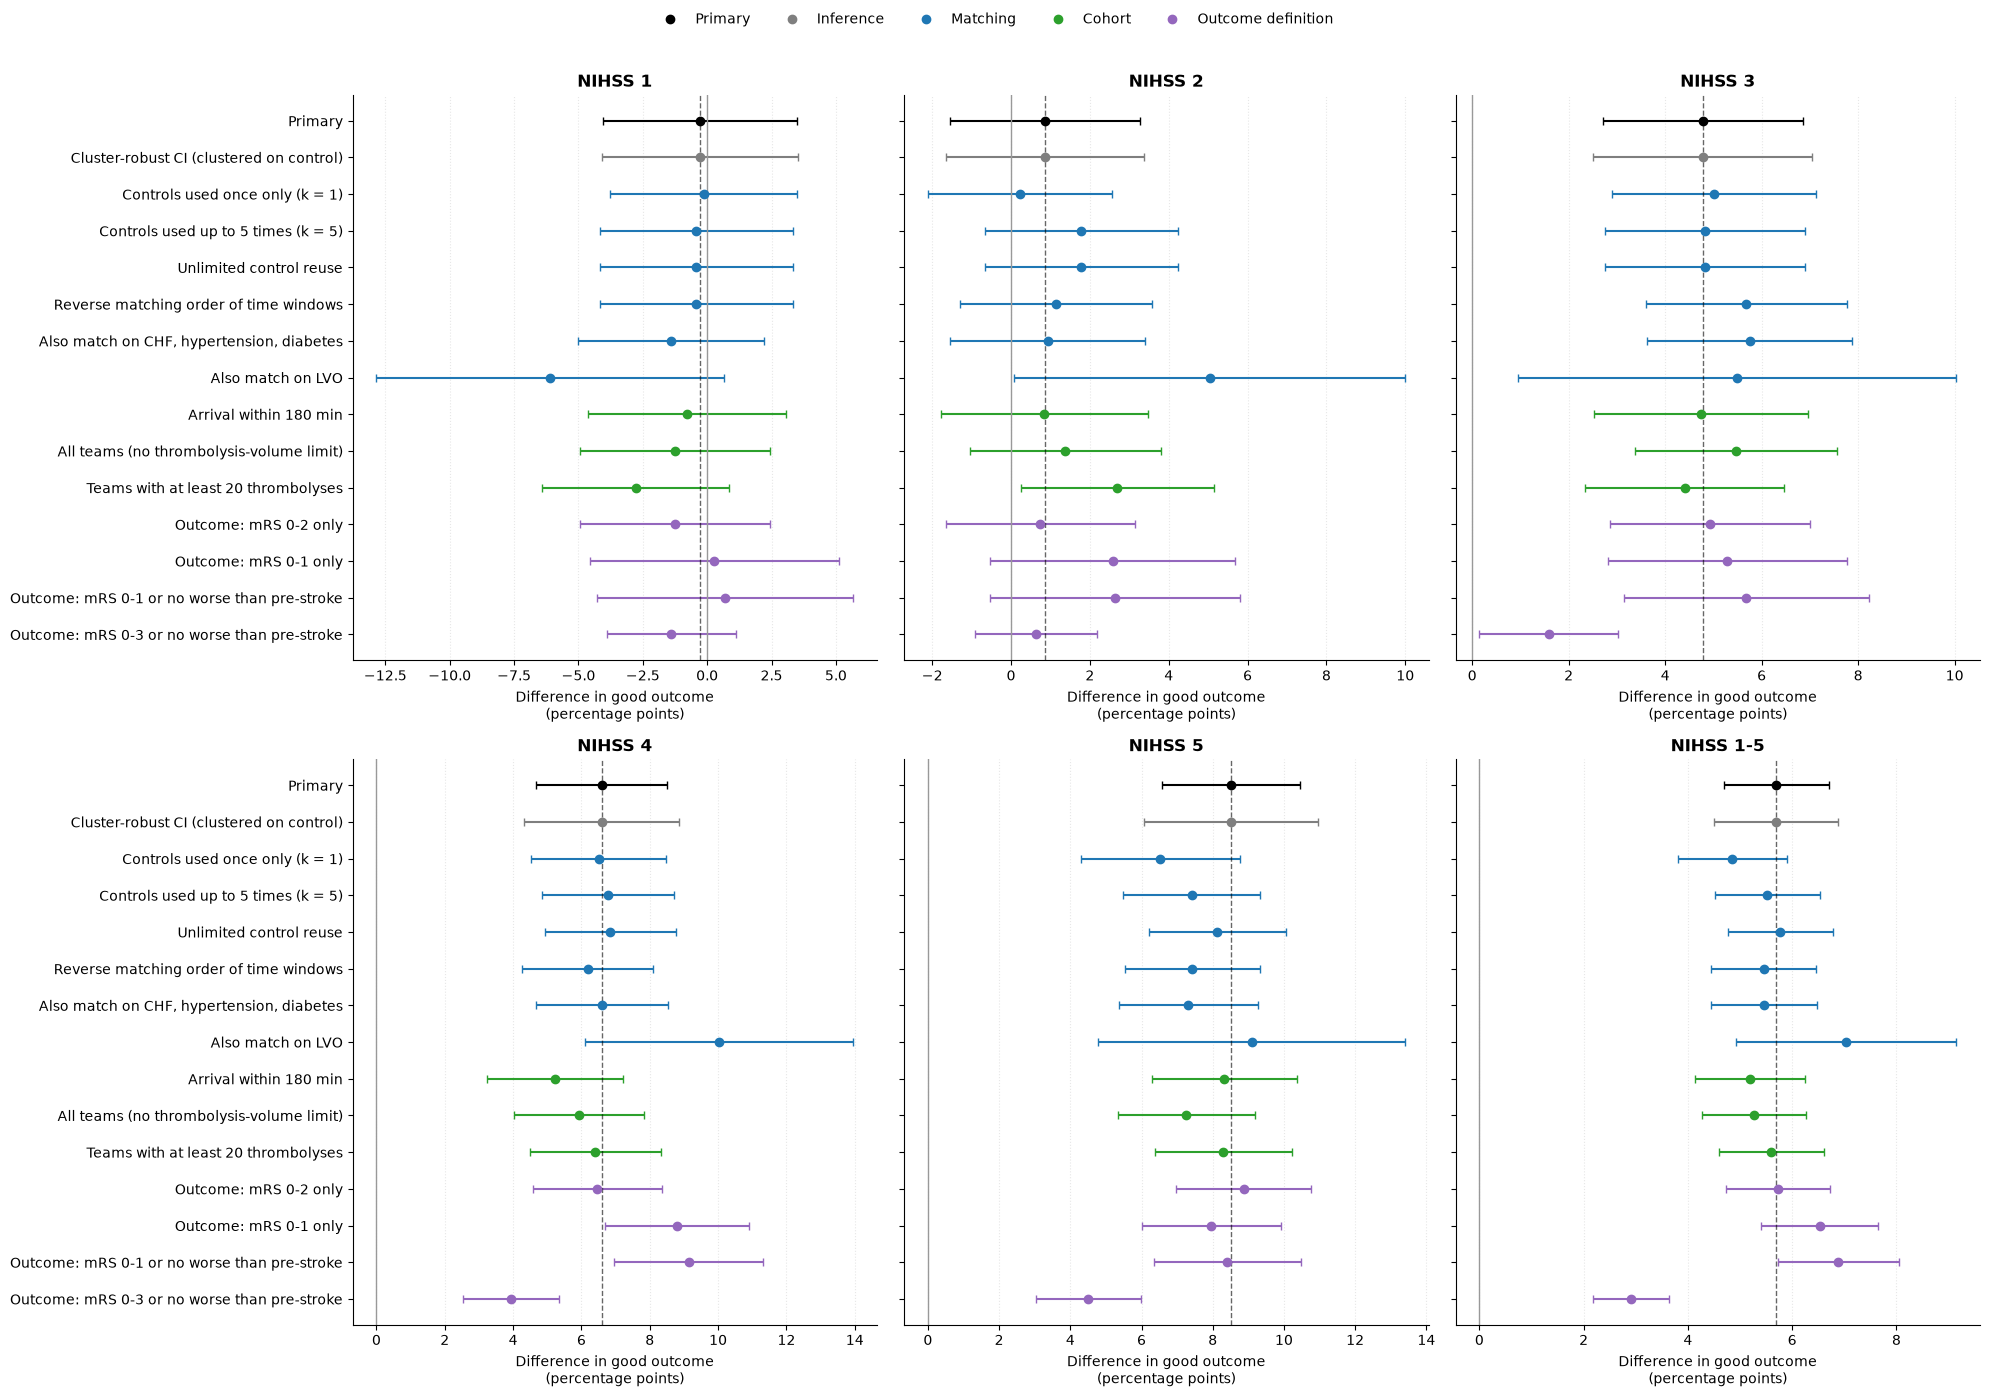

In [14]:
category_colours = {
    "Primary": "black",
    "Inference": "#7f7f7f",
    "Matching": "#1f77b4",
    "Cohort": "#2ca02c",
    "Outcome definition": "#9467bd",
}
fig, axes = plt.subplots(2, 3, figsize=(20, 14), sharey=True)
y_pos = {a: i for i, a in enumerate(analysis_order[::-1])}  # primary at the top

for ax, nihss_label in zip(axes.flat, nihss_order):
    df = sensitivity_df[sensitivity_df["nihss"] == nihss_label]
    for _, r in df.iterrows():
        colour = category_colours[r["category"]]
        ax.errorbar(100 * r["difference"], y_pos[r["analysis"]],
                    xerr=[[100 * (r["difference"] - r["ci_lower"])], [100 * (r["ci_upper"] - r["difference"])]],
                    fmt="o", color=colour, ecolor=colour, capsize=3, markersize=6)
    primary = df.loc[df["analysis"] == "Primary", "difference"].iloc[0]
    ax.axvline(100 * primary, color="black", linestyle="--", lw=1, alpha=0.6)
    ax.axvline(0, color="0.6", lw=1)
    ax.set_title(f"NIHSS {nihss_label}", fontweight="bold")
    ax.set_xlabel("Difference in good outcome\n(percentage points)")
    ax.grid(axis="x", alpha=0.3, linestyle=":")
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

axes[0, 0].set_yticks(list(y_pos.values()))
axes[0, 0].set_yticklabels(list(y_pos.keys()))
for ax in axes[:, 0]:
    ax.tick_params(labelleft=True)

handles = [plt.Line2D([], [], marker="o", color=c, linestyle="", label=k) for k, c in category_colours.items()]
fig.legend(handles=handles, loc="upper center", ncol=len(handles), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(f"{OUTPUT_DIR}/{prefix}_sensitivity.png", dpi=300)
plt.show()

**Results.** The forest plot shows the same pattern as the table. For NIHSS 3–5 and pooled NIHSS 1–5, every estimate lies to the right of zero, with the LVO-matched estimates the least precise and the mRS 0–3 estimates the smallest. For NIHSS 1 and 2, the estimates scatter around zero and nearly all CIs cross it.

### 6.3 Variation from the random choice of control

When several untreated patients match a thrombolysed patient, one is picked at random. Repeating the matching with 20 different random seeds shows how much the estimates move because of that choice alone. Seeds are spaced widely apart so that runs do not share random draws. The table gives the median, minimum and maximum difference across seeds (percentage points), the primary estimate, and the number of seeds whose 95% CI excludes zero.

In [15]:
N_SEEDS = 20
seed_df = pd.concat(
    [run_scenario(f"Seed {i}", "Seed", match_kwargs={"base_seed": 1_000_003 * i}) for i in range(1, N_SEEDS + 1)],
    ignore_index=True)
seed_df.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity_seeds.csv", index=False)

primary_effects = sensitivity_df[sensitivity_df["analysis"] == "Primary"].set_index("nihss")
seed_summary = (
    seed_df.groupby("nihss")["difference"]
    .agg(median="median", minimum="min", maximum="max")
    .mul(100).reindex(nihss_order).round(1)
)
seed_summary["primary"] = primary_effects["difference"].mul(100).round(1)
seed_summary["n_seeds_ci_excluding_zero"] = (
    seed_df.assign(excludes_zero=(seed_df["ci_lower"] > 0) | (seed_df["ci_upper"] < 0))
    .groupby("nihss")["excludes_zero"].sum()
)
seed_summary  # differences in percentage points

,median,minimum,maximum,primary,n_seeds_ci_excluding_zero
nihss,,,,,
1,-1.8,-2.8,0.8,-0.3,0
2,1.2,-0.5,3.4,0.9,3
3,5.2,4.0,6.8,4.8,20
4,6.1,4.9,7.1,6.6,20
5,7.3,6.4,8.9,8.5,20
1-5,5.4,4.9,5.9,5.7,20


**Results.**

* **Pooled NIHSS 1–5** is stable: +4.9 to +5.9 points across 20 seeds (median 5.4; primary seed 5.7).
* **Individual NIHSS scores** move more:
  * NIHSS 1: −2.8 to +0.8
  * NIHSS 2: −0.5 to +3.4 (CI excludes zero in only 3 of 20 seeds)
  * NIHSS 3: +4.0 to +6.8
  * NIHSS 4: +4.9 to +7.1
  * NIHSS 5: +6.4 to +8.9
* **NIHSS 3–5:** the CI excludes zero for every seed.

**Discussion.** The primary seed is within the range of the other seeds but is near the upper end at NIHSS 5 (8.5 vs median 7.3). Reporting the median over seeds, or averaging over several matchings, would give a more representative estimate.

### 6.4 E-values for unmeasured confounding

The E-value is the minimum strength of association, on the risk-ratio scale, that an unmeasured confounder would need with **both** thrombolysis and good outcome (beyond the matched variables) to fully explain away the observed effect. The E-value for the CI uses the confidence limit closest to no effect; a value of 1 means the CI already includes no effect.

Risk ratios are treated proportion / control proportion with a log-scale 95% CI that ignores the pairing.

In [16]:
def e_value(rr):
    rr = np.asarray(rr, dtype=float)
    rr = np.where(rr < 1, 1 / rr, rr)
    return rr + np.sqrt(rr * (rr - 1))

ev = primary_effects.reindex(nihss_order).reset_index()
p_t, p_c, n = ev["treated_good_outcome"], ev["control_good_outcome"], ev["matched_n"]
ev["risk_ratio"] = p_t / p_c
se_log_rr = np.sqrt((1 - p_t) / (n * p_t) + (1 - p_c) / (n * p_c))
ev["rr_ci_lower"] = np.exp(np.log(ev["risk_ratio"]) - 1.96 * se_log_rr)
ev["rr_ci_upper"] = np.exp(np.log(ev["risk_ratio"]) + 1.96 * se_log_rr)
ev["e_value"] = e_value(ev["risk_ratio"])
closest_limit = np.where(ev["risk_ratio"] >= 1, ev["rr_ci_lower"], ev["rr_ci_upper"])
crosses_null = (ev["rr_ci_lower"] <= 1) & (ev["rr_ci_upper"] >= 1)
ev["e_value_ci"] = np.where(crosses_null, 1.0, e_value(closest_limit))

ev_out = ev[["nihss", "matched_n", "risk_ratio", "rr_ci_lower", "rr_ci_upper", "e_value", "e_value_ci"]]
ev_out.to_csv(f"{OUTPUT_DIR}/{prefix}_e_values.csv", index=False)
ev_out.round(2)

,nihss,matched_n,risk_ratio,rr_ci_lower,rr_ci_upper,e_value,e_value_ci
0,1,722,1.00,0.95,1.04,1.06,1.00
1,2,1745,1.01,0.98,1.04,1.11,1.00
2,3,2781,1.06,1.03,1.09,1.32,1.22
3,4,3929,1.09,1.07,1.12,1.42,1.33
4,5,4172,1.13,1.10,1.17,1.52,1.43
5,1-5,13349,1.08,1.06,1.09,1.37,1.33


**Results.**

* **The E-values are modest:**
  * pooled NIHSS 1–5: 1.37 (CI limit 1.33)
  * NIHSS 3: 1.32 (CI limit 1.22)
  * NIHSS 4: 1.42 (CI limit 1.33)
  * NIHSS 5: 1.52 (CI limit 1.43)
  * NIHSS 1 and 2: the CI already includes no effect (CI E-value 1.00).

**Discussion.**

* **Why they are low:** good outcome is common in mild stroke (63–85% of controls), so even a clinically important difference of 5–9 percentage points is a risk ratio of only 1.06–1.13.
* **What that means:** an unmeasured confounder associated with both thrombolysis and good outcome by a risk ratio of about 1.3–1.5 could explain away the result. That is not a strong confounder.
* **Likely candidates** could bias the results in either direction:
  * whether the deficit is disabling
  * rapidly improving symptoms, a common reason not to treat; these patients usually do well, which would bias *against* thrombolysis
  * frailty not captured by pre-stroke mRS

### 6.5 Sensitivity to unmeasured confounding: sensemakr

Cinelli and Hazlett's omitted variable bias framework describes the strength of an unmeasured confounder by its partial R², the share of the remaining (residual) variance of treatment and of outcome that it explains. It gives:

* **Robustness value RV_q** (q = 1): the minimum partial R² that a confounder would need with *both* thrombolysis and good outcome to reduce the estimate to zero.
* **RV_q,alpha**: the same, to make the 95% confidence interval include zero.
* **Partial R² of treatment with outcome**: an extreme-scenario bound. A confounder that explained all the remaining variation in outcome would still need at least this partial R² with thrombolysis to remove the effect.
* **Benchmark bounds**: the adjusted estimate (with 95% CI) if a confounder were 1, 2 or 3 times as strongly associated with thrombolysis and with outcome as an observed covariate.

Unlike E-values, robustness values are on the partial R² scale, so they are not limited by the high baseline rate of good outcome in mild stroke.

The framework applies to linear regression. For each NIHSS score, and pooled NIHSS 1–5, a linear probability model is fitted to the matched pairs for all thrombolysed patients (good outcome ~ thrombolysed + baseline features: the matching features plus heart failure, hypertension and diabetes). Controls used more than once appear once per use, as in the primary analysis. Benchmarks are pre-stroke mRS, NIHSS and age. Within a single NIHSS score, NIHSS is constant, so it is dropped from that model and from its benchmarks.

The first cell implements the formulas of the sensemakr package directly, because the Python package (PySensemakr 0.0.8) is not compatible with pandas 3. The second fits the models and tabulates robustness values and benchmark bounds, and the third draws the sensitivity contours.

In [17]:
from scipy import stats as _stats
import statsmodels.api as _sm


def sensemakr_analysis(model, treatment, benchmarks, kd=(1, 2, 3), q=1.0, alpha=0.05):
    """Cinelli & Hazlett (2020) omitted-variable-bias sensitivity analysis for one OLS coefficient.

    Implements the formulas of the sensemakr package directly (the PySensemakr package is not
    compatible with pandas 3). Returns a one-row DataFrame of sensitivity statistics and a
    DataFrame of bounds: the adjusted estimate if an unobserved confounder were kd times as
    strongly associated with treatment and with outcome as each benchmark covariate.
    """
    est, se, t = model.params[treatment], model.bse[treatment], model.tvalues[treatment]
    dof = model.df_resid
    t_crit = _stats.t.ppf(1 - alpha / 2, dof - 1)

    # Partial R2 of treatment with outcome, and robustness values
    r2yd_x = t**2 / (t**2 + dof)
    f_q = q * abs(t) / np.sqrt(dof)
    rv_q = 0.5 * (np.sqrt(f_q**4 + 4 * f_q**2) - f_q**2)
    f_crit = t_crit / np.sqrt(dof - 1)
    f_qa = f_q - f_crit
    if f_qa < 0:
        rv_qa = 0.0
    elif f_q > 1 / f_crit:  # extreme case (very large t), as in the sensemakr package
        rv_qa = (f_q**2 - f_crit**2) / (1 + f_q**2)
    else:
        rv_qa = 0.5 * (np.sqrt(f_qa**4 + 4 * f_qa**2) - f_qa**2)
    sens_stats = pd.DataFrame([{
        "estimate": est, "se": se, "t": t, "dof": dof, "t_crit": t_crit,
        "r2yd_x": r2yd_x, "rv_q": rv_q, "rv_qa": rv_qa,
    }])

    # Benchmark bounds: partial R2 of each benchmark with treatment (given other covariates)
    # and with outcome (given treatment and other covariates)
    exog = pd.DataFrame(model.model.exog, columns=model.model.exog_names)
    treatment_model = _sm.OLS(exog[treatment], exog.drop(columns=treatment)).fit()
    rows = []
    for b in benchmarks:
        t_dx = treatment_model.tvalues[b]
        r2dxj_x = t_dx**2 / (t_dx**2 + treatment_model.df_resid)
        r2yxj_dx = model.tvalues[b]**2 / (model.tvalues[b]**2 + dof)
        for k in kd:
            row = {"benchmark": b, "kd": k}
            if k * r2dxj_x >= 1:
                rows.append(row)
                continue
            r2dz_x = k * r2dxj_x / (1 - r2dxj_x)
            r2zxj_xd = k * r2dxj_x**2 / ((1 - k * r2dxj_x) * (1 - r2dxj_x))
            r2yz_dx = min(1.0, ((np.sqrt(k) + np.sqrt(r2zxj_xd)) / np.sqrt(1 - r2zxj_xd))**2
                          * r2yxj_dx / (1 - r2yxj_dx))
            bias = se * np.sqrt(r2yz_dx * r2dz_x / (1 - r2dz_x) * dof)
            adj_est = np.sign(est) * (abs(est) - bias)
            adj_se = se * np.sqrt((1 - r2yz_dx) / (1 - r2dz_x) * dof / (dof - 1))
            row.update({"r2dz_x": r2dz_x, "r2yz_dx": r2yz_dx, "adjusted_estimate": adj_est,
                        "adjusted_ci_lower": adj_est - t_crit * adj_se,
                        "adjusted_ci_upper": adj_est + t_crit * adj_se})
            rows.append(row)
    return sens_stats, pd.DataFrame(rows)


def adjusted_estimate_grid(est, se, dof, r2dz_x, r2yz_dx):
    """Adjusted estimate (bias towards zero) over a grid of confounder partial R2 values."""
    bias = se * np.sqrt(r2yz_dx * r2dz_x / (1 - r2dz_x) * dof)
    return np.sign(est) * (abs(est) - bias)


BENCHMARK_MARKERS = {"prior_disability": "o", "stroke_severity": "s", "age": "^", "onset_to_scan_time": "D"}
BENCHMARK_NAMES = {"prior_disability": "pre-stroke mRS", "stroke_severity": "NIHSS", "age": "age",
                   "onset_to_scan_time": "onset-to-scan time"}


def plot_sensemakr_contours(sens_stats, sens_bounds, labels, filename, scale=100, unit="percentage points"):
    """One contour plot per treatment strategy: adjusted estimate against the partial R2 of a
    hypothetical confounder with treatment (x) and with outcome (y). The red dashed line is
    where the estimate would fall to zero; markers show confounders 1x, 2x and 3x as strong
    as each benchmark covariate."""
    strategies = list(sens_stats.index)
    ncols = 4
    nrows = int(np.ceil(len(strategies) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.9 * nrows), squeeze=False)
    for ax, strategy in zip(axes.flat, strategies):
        st = sens_stats.loc[strategy]
        b = sens_bounds[(sens_bounds["treatment_group"] == strategy)].dropna(subset=["r2dz_x"])
        lim = max(0.05, 1.2 * max(b["r2dz_x"].max(), b["r2yz_dx"].max(), st["rv_q"]))
        lim = min(lim, 0.95)
        grid = np.linspace(0, lim, 201)
        gx, gy = np.meshgrid(grid, grid)
        z = scale * adjusted_estimate_grid(st["estimate"], st["se"], st["dof"], gx, gy)
        cs = ax.contour(gx, gy, z, levels=8, colors="grey", linewidths=0.7)
        ax.clabel(cs, fontsize=7, fmt="%.0f")
        ax.contour(gx, gy, z, levels=[0], colors="red", linestyles="--", linewidths=1.3)
        for _, r in b.iterrows():
            ax.plot(r["r2dz_x"], r["r2yz_dx"], BENCHMARK_MARKERS.get(r["benchmark"], "x"),
                    color="black", ms=4 + r["kd"])
        ax.plot(0, 0, "*", color="tab:blue", ms=9)
        ax.set_xlim(0, lim)
        ax.set_ylim(0, lim)
        ax.set_title(labels.get(strategy, strategy).replace("\n", " "), fontsize=10)
        ax.set_xlabel("Partial R² of confounder with treatment", fontsize=8)
        ax.set_ylabel("Partial R² of confounder with outcome", fontsize=8)
        ax.tick_params(labelsize=7)
    for ax in axes.flat[len(strategies):]:
        ax.axis("off")
    handles = [plt.Line2D([], [], color="red", linestyle="--", label="Adjusted estimate = 0"),
               plt.Line2D([], [], marker="*", color="tab:blue", linestyle="", label="Unadjusted estimate")]
    used = sorted(set(sens_bounds["benchmark"]), key=list(BENCHMARK_MARKERS).index)
    handles += [plt.Line2D([], [], marker=BENCHMARK_MARKERS.get(b, "x"), color="black", linestyle="",
                           label=f"1x, 2x, 3x {BENCHMARK_NAMES.get(b, b)}") for b in used]
    fig.legend(handles=handles, loc="lower right", fontsize=8, frameon=False)
    fig.suptitle(f"Sensitivity contours: adjusted effect ({unit})", fontsize=12)
    fig.tight_layout()
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()


def format_sensemakr_tables(sens_stats, sens_bounds, labels, scale=100, decimals=1):
    """Publication tables: robustness statistics, and adjusted estimates for each benchmark."""
    fmt = lambda x: f"{scale * x:.{decimals}f}"
    summary = pd.DataFrame({
        "n": sens_stats["n"].astype(int).to_numpy(),
        "estimate (95% CI)": [f"{fmt(r.estimate)} ({fmt(r.estimate - r.t_crit * r.se)}, {fmt(r.estimate + r.t_crit * r.se)})"
                              for r in sens_stats.itertuples()],
        "partial R2 of treatment (%)": (100 * sens_stats["r2yd_x"]).round(2).to_numpy(),
        "RV_q (%)": (100 * sens_stats["rv_q"]).round(1).to_numpy(),
        "RV_q,alpha (%)": (100 * sens_stats["rv_qa"]).round(1).to_numpy(),
    }, index=[labels.get(s, s).replace("\n", " ") for s in sens_stats.index])
    b = sens_bounds.copy()
    b["adjusted (95% CI)"] = [
        "" if pd.isna(r.adjusted_estimate) else
        f"{fmt(r.adjusted_estimate)} ({fmt(r.adjusted_ci_lower)}, {fmt(r.adjusted_ci_upper)})"
        for r in b.itertuples()]
    b["bound"] = b["kd"].astype(str) + "x " + b["benchmark"].map(lambda x: BENCHMARK_NAMES.get(x, x))
    bounds_table = b.pivot(index="treatment_group", columns="bound", values="adjusted (95% CI)")
    bounds_table = bounds_table.reindex(index=list(sens_stats.index),
                                        columns=list(dict.fromkeys(b["bound"])))
    bounds_table.index = [labels.get(s, s).replace("\n", " ") for s in bounds_table.index]
    return summary, bounds_table

In [18]:
# Linear probability model in the matched pairs: good outcome ~ thrombolysed + baseline features.
# One model per NIHSS score (NIHSS of the pair) and one for pooled NIHSS 1-5, all thrombolysed patients (<= 360 min).
# Controls used more than once appear once per use, as in the primary analysis.
SENS_BENCHMARKS = ["prior_disability", "stroke_severity", "age"]
SENS_LABELS = {n: f"NIHSS {n}" for n in nihss_order}

# matched_treated and matched_untreated (balance section) are aligned row by row
lpm_data = pd.concat([matched_treated.assign(treated=1), matched_untreated.assign(treated=0)], ignore_index=True)
lpm_data["pair_nihss"] = np.concatenate([matched_treated["stroke_severity"].to_numpy()] * 2)

sens_rows, sens_bound_rows = [], []
for nihss_label in nihss_order:
    df = lpm_data if nihss_label == "1-5" else lpm_data[lpm_data["pair_nihss"] == int(nihss_label)]
    df = df[["outcome_target", "treated"] + BASELINE_FEATURES].apply(pd.to_numeric, errors="coerce").dropna()
    covariates = [f for f in BASELINE_FEATURES if df[f].nunique() > 1]  # drops NIHSS within a single score
    lpm = sm.OLS(df["outcome_target"], sm.add_constant(df[["treated"] + covariates])).fit()
    stats_row, bounds = sensemakr_analysis(lpm, "treated", [b for b in SENS_BENCHMARKS if b in covariates])
    sens_rows.append(stats_row.assign(treatment_group=nihss_label, n=len(df)))
    sens_bound_rows.append(bounds.assign(treatment_group=nihss_label))

sensemakr_stats = pd.concat(sens_rows).set_index("treatment_group")
sensemakr_bounds = pd.concat(sens_bound_rows, ignore_index=True)
sensemakr_stats.to_csv(f"{OUTPUT_DIR}/{prefix}_sensemakr.csv")
sensemakr_bounds.to_csv(f"{OUTPUT_DIR}/{prefix}_sensemakr_bounds.csv", index=False)

sensemakr_summary, sensemakr_bounds_table = format_sensemakr_tables(sensemakr_stats, sensemakr_bounds, SENS_LABELS)
display(sensemakr_summary)
display(sensemakr_bounds_table)

,n,estimate (95% CI),partial R2 of treatment (%),RV_q (%),"RV_q,alpha (%)"
NIHSS 1,1444,"-0.5 (-4.1, 3.2)",0.00,0.7,0.0
NIHSS 2,3490,"0.5 (-1.9, 3.0)",0.01,0.7,0.0
NIHSS 3,5562,"4.6 (2.5, 6.7)",0.33,5.6,3.1
NIHSS 4,7858,"6.4 (4.5, 8.3)",0.54,7.1,5.1
NIHSS 5,8344,"8.4 (6.5, 10.4)",0.85,8.8,6.9
NIHSS 1-5,26698,"5.5 (4.5, 6.5)",0.43,6.3,5.2


bound,1x pre-stroke mRS,2x pre-stroke mRS,3x pre-stroke mRS,1x age,2x age,3x age,1x NIHSS,2x NIHSS,3x NIHSS
NIHSS 1,"-0.4 (-4.1, 3.2)","-0.4 (-4.0, 3.2)","-0.4 (-4.0, 3.2)","-0.4 (-4.0, 3.2)","-0.4 (-3.9, 3.2)","-0.3 (-3.8, 3.2)",NaN,NaN,NaN
NIHSS 2,"0.5 (-1.9, 2.9)","0.5 (-1.9, 2.9)","0.5 (-2.0, 2.9)","0.5 (-1.9, 2.9)","0.4 (-2.0, 2.8)","0.3 (-2.0, 2.7)",NaN,NaN,NaN
NIHSS 3,"4.6 (2.5, 6.7)","4.5 (2.5, 6.6)","4.5 (2.4, 6.6)","4.6 (2.5, 6.6)","4.5 (2.5, 6.6)","4.5 (2.4, 6.5)",NaN,NaN,NaN
NIHSS 4,"6.4 (4.4, 8.3)","6.3 (4.4, 8.2)","6.3 (4.4, 8.2)","6.3 (4.4, 8.2)","6.3 (4.4, 8.1)","6.2 (4.4, 8.0)",NaN,NaN,NaN
NIHSS 5,"8.4 (6.5, 10.4)","8.4 (6.5, 10.4)","8.4 (6.5, 10.4)","8.4 (6.5, 10.3)","8.4 (6.5, 10.2)","8.3 (6.5, 10.2)",NaN,NaN,NaN
NIHSS 1-5,"5.5 (4.5, 6.5)","5.5 (4.5, 6.5)","5.5 (4.5, 6.5)","5.5 (4.5, 6.5)","5.4 (4.4, 6.4)","5.4 (4.4, 6.3)","5.5 (4.5, 6.5)","5.5 (4.5, 6.5)","5.5 (4.5, 6.5)"


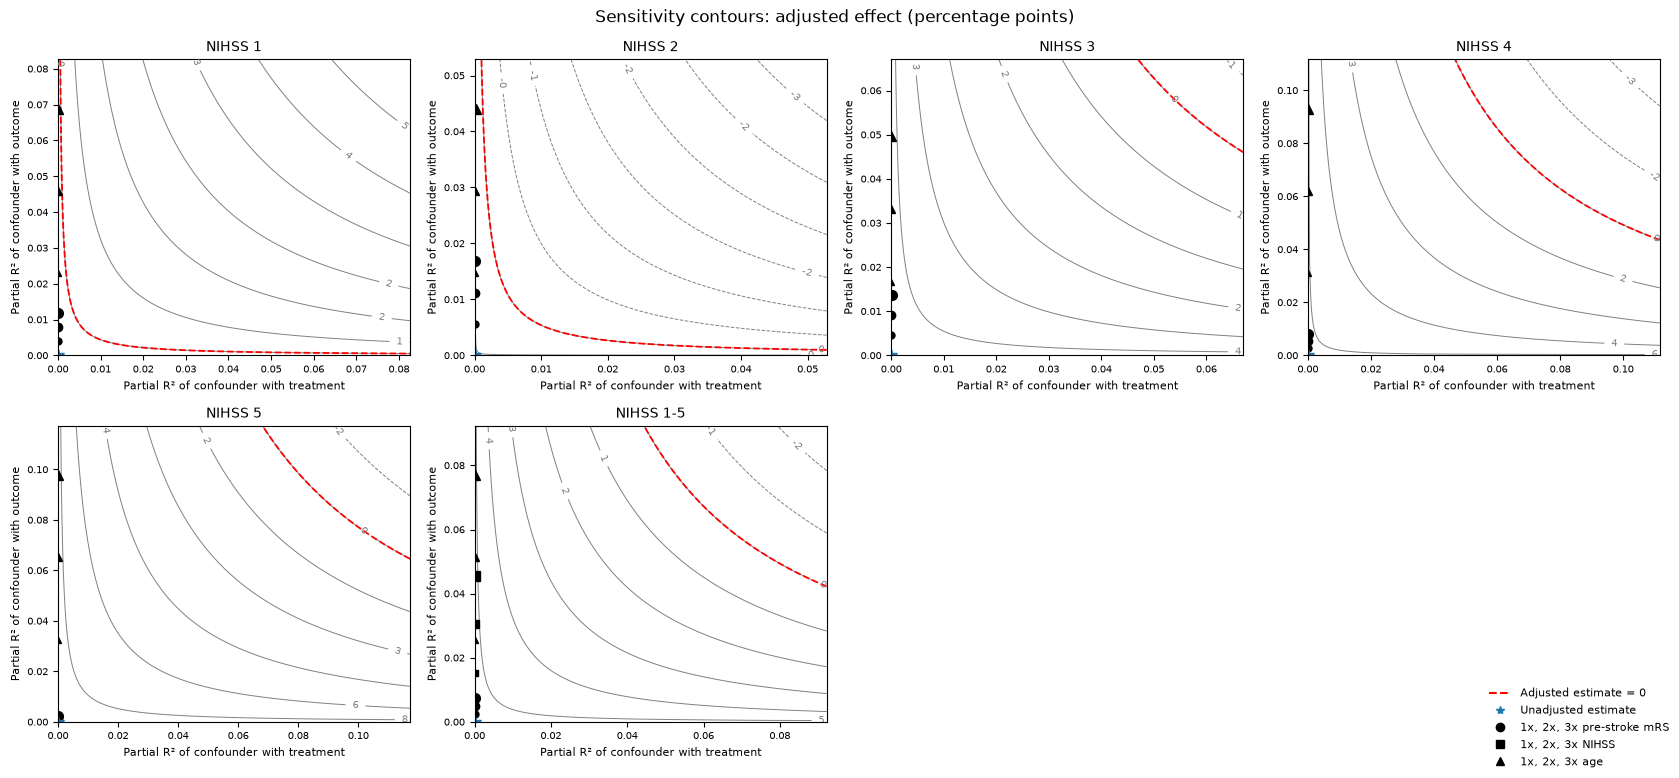

In [19]:
plot_sensemakr_contours(sensemakr_stats, sensemakr_bounds, SENS_LABELS,
                        f"{OUTPUT_DIR}/{prefix}_sensemakr_contours.png")

**Results.**

* The linear probability model estimates agree with the primary paired differences to within 0.4 percentage points.
* **Robustness values** are 5.6% (NIHSS 3), 7.1% (NIHSS 4) and 8.8% (NIHSS 5), and 6.3% pooled. For NIHSS 5, an unmeasured confounder would need to explain at least 8.8% of the remaining variance of both thrombolysis and good outcome to reduce the effect to zero, and 6.9% to make it no longer statistically significant.
* **Most fragile:** NIHSS 3 (RV_q,alpha 3.1%). At NIHSS 1 and 2 the robustness values are 0.7% and RV_q,alpha is 0, because the CIs already include zero.
* **Benchmark bounds** change the estimates by at most 0.3 percentage points, even for a confounder three times as strong as pre-stroke mRS or age (for example NIHSS 4: 6.4 → 6.2). NIHSS is a benchmark only in the pooled model, where it changes the estimate by less than 0.1 points.
* **Contour plot:** each panel shows the adjusted estimate (percentage points) for a hypothetical confounder with a given partial R² with thrombolysis (horizontal axis) and with outcome (vertical axis). The red dashed line is where the effect would fall to zero. The benchmark markers lie close to the origin, well inside the red line.

**Discussion.** Unlike E-values, robustness values are not compressed by the high rate of good outcome in mild stroke, and they also show that the results are only moderately robust to unmeasured confounding. The benchmarks are of limited use after exact matching: matching makes pre-stroke mRS, age and NIHSS almost unrelated to thrombolysis within the matched pairs, so confounders as strong as these change the estimates very little. The leave-one-out analysis (6.6) shows instead how much the results depend on matching for these features.

### 6.6 Leave-one-out analysis of the main confounders

Each of the three strongest measured confounders (NIHSS, age and pre-stroke mRS) is removed from the matching features in turn, and the matching and comparison are repeated. Leaving out a measured confounder is a deliberate misspecification: the change in the estimate shows how much each result depends on matching for that confounder, and so how much bias an unmeasured confounder of similar strength, acting in the same direction, could cause. Removing a matching feature also makes matching easier, so a higher percentage of treated patients is matched.

When NIHSS is left out, pairs are still reported by the thrombolysed patient's NIHSS, but the matched control can have any NIHSS from 1 to 5.

In [20]:
# Leave-one-out sensitivity analysis: remove each main confounder from the matching features in turn
LOO_FEATURES = {
    "Without NIHSS": "stroke_severity",
    "Without age": "age",
    "Without pre-stroke mRS": "prior_disability",
}
loo_results = [effects_by_nihss(pairs, treated_all, "Primary", "Leave one out")]
for label, feature in LOO_FEATURES.items():
    features = [f for f in MATCHING_FEATURES if f != feature]
    loo_results.append(run_scenario(label, "Leave one out", match_kwargs={"matching_features": features}))
    print(f"Completed: {label}")

loo_df = pd.concat(loo_results, ignore_index=True)
primary_difference = loo_df[loo_df["analysis"] == "Primary"].set_index("nihss")["difference"]
loo_df["change_pp"] = 100 * (loo_df["difference"] - loo_df["nihss"].map(primary_difference))
loo_df["estimate_pp"] = [fmt_pct(d, l, u) for d, l, u in loo_df[["difference", "ci_lower", "ci_upper"]].to_numpy()]
loo_df.to_csv(f"{OUTPUT_DIR}/{prefix}_leave_one_out.csv", index=False)

loo_columns = ["Primary", *LOO_FEATURES]
for values, title in [("estimate_pp", "Difference in good outcome, percentage points (95% CI)"),
                      ("change_pp", "Change from the primary estimate, percentage points"),
                      ("percent_matched", "Percentage of treated patients matched")]:
    print(title)
    display(loo_df.pivot(index="nihss", columns="analysis", values=values)
            .reindex(index=nihss_order, columns=loo_columns).round(1))

Completed: Without NIHSS
Completed: Without age
Completed: Without pre-stroke mRS
Difference in good outcome, percentage points (95% CI)


analysis,Primary,Without NIHSS,Without age,Without pre-stroke mRS
nihss,,,,
1,"-0.3 (-4.0, 3.5)","6.4 (2.5, 10.2)","-0.7 (-4.4, 3.0)","-1.5 (-5.2, 2.2)"
2,"0.9 (-1.6, 3.3)","3.4 (0.9, 5.9)","2.8 (0.3, 5.3)","0.7 (-1.7, 3.2)"
3,"4.8 (2.7, 6.9)","3.7 (1.6, 5.8)","7.5 (5.4, 9.7)","5.5 (3.4, 7.6)"
4,"6.6 (4.7, 8.5)","-0.9 (-2.7, 0.9)","6.2 (4.3, 8.2)","6.7 (4.8, 8.7)"
5,"8.5 (6.6, 10.5)","-4.7 (-6.5, -2.9)","9.8 (7.7, 11.8)","7.5 (5.6, 9.5)"
1-5,"5.7 (4.7, 6.7)","-0.2 (-1.1, 0.8)","6.8 (5.8, 7.8)","5.5 (4.5, 6.5)"


Change from the primary estimate, percentage points


analysis,Primary,Without NIHSS,Without age,Without pre-stroke mRS
nihss,,,,
1,0.0,6.6,-0.4,-1.2
2,0.0,2.6,1.9,-0.1
3,0.0,-1.1,2.8,0.8
4,0.0,-7.5,-0.3,0.1
5,0.0,-13.2,1.2,-1.0
1-5,0.0,-5.9,1.1,-0.2


Percentage of treated patients matched


analysis,Primary,Without NIHSS,Without age,Without pre-stroke mRS
nihss,,,,
1,100.0,100.0,100.0,100.0
2,99.9,99.9,100.0,100.0
3,99.9,100.0,100.0,99.9
4,99.4,100.0,100.0,99.8
5,100.0,100.0,100.0,100.0
1-5,99.8,100.0,100.0,99.9


**Results.**

* **Leaving out pre-stroke mRS** changes the estimates by 1.2 percentage points or less.
* **Leaving out age** changes them by −0.4 to +2.8 points, the largest at NIHSS 3 (4.8 → 7.5). NIHSS 2 then reaches +2.8 (0.3 to 5.3).
* **Leaving out NIHSS** changes the estimates a lot, in opposite directions at the two ends of the range:
  * NIHSS 1: −0.3 → +6.4 (2.5 to 10.2); NIHSS 2: +0.9 → +3.4 (0.9 to 5.9)
  * NIHSS 3: +4.8 → +3.7 (1.6 to 5.8)
  * NIHSS 4: +6.6 → −0.9 (−2.7 to 0.9); NIHSS 5: +8.5 → −4.7 (−6.5 to −2.9)
  * pooled NIHSS 1–5: +5.7 → −0.2 (−1.1 to 0.8)
* **Matching rates:** without any one matching feature, 99.8–100% of thrombolysed patients are matched.

**Discussion.** Without NIHSS, thrombolysed patients are compared with untreated patients of any NIHSS from 1 to 5, who are mostly NIHSS 1–3. Thrombolysed NIHSS 1–2 patients are therefore compared with controls who tend to have more severe strokes (inflating the benefit), and thrombolysed NIHSS 4–5 patients with controls who tend to have milder strokes (hiding it); pooled, the benefit disappears. The results depend heavily on matching exactly for stroke severity, and an unmeasured confounder about as strong as NIHSS (for example whether the deficit is disabling) could change them substantially. Age and pre-stroke mRS matter much less.

## 7. Summary of observations, conclusions and limitations

### Observations

* **Cohort and matching:** 58,389 patients are eligible, of whom 13,380 (22.9%) were thrombolysed; the proportion thrombolysed rises from 6.6% at NIHSS 1 to 44.3% at NIHSS 5. 99.6–100% of thrombolysed patients are matched, and the unmatched comorbidities are well balanced (thrombolysed patients have slightly less diabetes, SMD down to −0.10).
* **By NIHSS (all thrombolysed patients):** the difference in good outcome is −0.3 at NIHSS 1, +0.9 at NIHSS 2, +4.8 at NIHSS 3, +6.6 at NIHSS 4 and +8.5 at NIHSS 5 percentage points; the CIs exclude zero only for NIHSS 3–5. Pooled over NIHSS 1–5 it is +5.7 (4.7 to 6.7).
* **By time window (pooled NIHSS 1–5):** +6.8 within 180 minutes, +4.6 at 180–270 minutes and +2.1 (CI includes zero; 475 pairs) at 270–360 minutes. The time effect is clearest at NIHSS 5 (+10.9 vs +5.2 in the first two windows).
* **Analytic choices:** the NIHSS 3–5 CIs exclude zero in every analysis of inference, control reuse, matching order, comorbidity and LVO matching, cohort definition and outcome definition, and for all 20 random seeds. The NIHSS 1 CIs include zero in every analysis; the NIHSS 2 CI only narrowly excludes zero in two.
* **Outcome definition:** the stricter mRS 0–1 outcome gives slightly larger differences (pooled +6.5); the looser mRS 0–3 outcome gives smaller ones (pooled +2.9).
* **Random choice of control:** pooled estimates vary little (+4.9 to +5.9 across seeds); individual NIHSS estimates vary by 2.2 to 3.9 points.
* **Confounding:** E-values at NIHSS 3–5 are 1.32 to 1.52 and sensemakr robustness values 5.6% to 8.8%. Leaving NIHSS out of the matching removes the pooled benefit (+5.7 → −0.2) and reverses it at NIHSS 5; leaving out age or pre-stroke mRS changes the estimates by 2.8 points or less.

### Conclusions

* **NIHSS 3–5:** in patients with mild ischaemic stroke arriving within 4 hours, thrombolysis is associated with more good outcomes at discharge. The difference rises with NIHSS (+4.8, +6.6 and +8.5 percentage points at NIHSS 3, 4 and 5) and is largest when treatment is given within 180 minutes.
* **NIHSS 1:** there is no evidence of benefit.
* **NIHSS 2:** any benefit is small. The CIs rule out more than about 3 points for good outcome, or about 6 points for excellent outcome (mRS 0–1).
* **Robustness:** these findings are consistent across matching choices, cohort definitions, outcome definitions and random seeds.
* **Confounding:** the findings depend heavily on matching exactly for NIHSS, and unmeasured confounding of moderate strength could explain them.

### Limitations

* **Unmeasured confounding.**
  * Not recorded or not matched:
    * whether the deficit is disabling (for example aphasia or hemianopia at a low NIHSS)
    * rapidly improving symptoms
    * imaging findings
    * frailty
  * At low NIHSS, clinicians may thrombolyse mainly patients with disabling deficits, whose outcomes would otherwise be worse. That could hide a real benefit at NIHSS 1–2, or other factors could bias the results in either direction.
  * The modest E-values and robustness values mean such confounding does not have to be strong to matter, and the leave-one-out analysis shows how strongly the results depend on accounting for severity.
* **Outcome at discharge, and a ceiling effect.** Most controls at NIHSS 1–2 already have a good outcome. Discharge mRS may be too coarse to detect small benefits, and 90-day outcomes are not available.
* **Harms are not analysed.** The net benefit of thrombolysis at low NIHSS also depends on symptomatic intracranial haemorrhage, which this notebook does not compare.
* **Multiple comparisons.** There are 24 rows in the main table and 15 rows in the sensitivity table. P values are unadjusted, and small rows (especially 270–360 min) should not be over-interpreted.
* **LVO not matched.** LVO status is not used in the primary matching; matching on it is possible for only about a fifth of thrombolysed patients.
* **Matching choices.**
  * The shared limit on control reuse makes results depend slightly on matching order.
  * The random choice of control moves individual NIHSS estimates by up to about 4 points.